# AlphaGenome for breast cancer risk variants: seminar figures

Slide-ready figures (16:9, large fonts, white background) applying AlphaGenome and the
AlphaGenome Atlas to the BRIDGES 34 breast cancer genes. Every figure is saved as PNG
(and PDF) in `seminar_figures/`.

| Figure | Message |
|---|---|
| 1 | AlphaGenome predicts functional genomics tracks from DNA sequence alone |
| 2 | It predicts what a single variant does: an MLH1 promoter VUS, and a BRCA1 non-coding VUS |
| 3 | The Atlas gives every possible SNV: in silico mutagenesis across the BRCA1 locus |
| 4 | Base resolution: the BRCA1 core promoter |
| 5 | Promoter mutagenesis across all 34 BRIDGES genes |
| 6 | Coding vs non-coding impact in BRCA1, BRCA2 and TP53 |
| 7 | Our Seqweaver variants against AlphaGenome |
| 8 | Top candidate regulatory variants |
| 9 | AVI score on ClinVar variants in the 34 genes |
| 10 | Why a variant is flagged: AVI feature contributions |

All Atlas queries are cached under `data/alphagenome_atlas/`, so re-running is fast.
Predictions are for research use only, not for clinical decision-making.

In [20]:
import concurrent.futures
import pathlib
import re
import subprocess
import time

from alphagenome.atlas import atlas
from alphagenome.data import genome
from alphagenome.models import dna_client
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
from pyliftover import LiftOver

ROOT = pathlib.Path('/storage/mathelierarea/processed/eirikhoy/action_var')
FIGDIR = pathlib.Path('seminar_figures')
FIGDIR.mkdir(exist_ok=True)
ATLAS_CACHE = ROOT / 'data/alphagenome_atlas'

ONTOLOGY = 'CL:0002327'  # mammary epithelial cell
CELL = 'mammary epithelial cells'
# The 34 BRIDGES genes, GENCODE v46 names (FAM175A=ABRAXAS1, BRE=BABAM2, MRE11A=MRE11).
BRIDGES_GENES = [
    'ABRAXAS1', 'AKT1', 'ATM', 'BABAM2', 'BARD1', 'BRCA1', 'BRCA2', 'BRIP1', 'CDH1',
    'CHEK2', 'EPCAM', 'FANCC', 'FANCM', 'GEN1', 'MEN1', 'MLH1', 'MRE11', 'MSH2', 'MSH6',
    'MUTYH', 'NBN', 'NF1', 'PALB2', 'PIK3CA', 'PMS2', 'PTEN', 'RAD50', 'RAD51C',
    'RAD51D', 'RECQL', 'RINT1', 'STK11', 'TP53', 'XRCC2',
]
# Whole-locus mutagenesis: gene body plus flanking non-coding sequence (hg38).
LOCI = {
    'BRCA1': genome.Interval('chr17', 43_030_000, 43_150_000),
    'BRCA2': genome.Interval('chr13', 32_300_000, 32_412_000),
    'TP53': genome.Interval('chr17', 7_650_000, 7_702_000),
}

API_KEY = (ROOT / 'resources/API_KEY').read_text().strip()
dna_model = dna_client.create(API_KEY)
atlas_client = atlas.create(API_KEY, timeout=60)

In [21]:
# Slide style: 16:9, large type, white background.
SLIDE = (13.33, 7.5)
INK, SECONDARY, MUTED, GRID, AXIS = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
UP, DOWN, BLUE = '#e34948', '#2a78d6', '#2a78d6'
NUC_COLORS = {'A': '#2a78d6', 'C': '#eb6834', 'G': '#1baf7a', 'T': '#eda100'}
SERIES = ['#2a78d6', '#eb6834', '#1baf7a']
SEQUENTIAL = LinearSegmentedColormap.from_list(
    'blues', ['#ffffff', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b']
)

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'axes.edgecolor': AXIS, 'axes.labelcolor': SECONDARY,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelcolor': SECONDARY, 'ytick.labelcolor': SECONDARY,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 14, 'axes.titlesize': 15, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.labelsize': 14,
    'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 13,
    'figure.titlesize': 20, 'figure.titleweight': 'bold',
})


def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(FIGDIR / f'{name}.{ext}', dpi=250, bbox_inches='tight')


def headline(fig, title, subtitle=None):
    """Left-aligned slide title and optional subtitle."""
    fig.suptitle(title, x=0.06, y=0.995, ha='left', va='top')
    if subtitle:
        fig.text(0.06, 0.935, subtitle, ha='left', va='top', fontsize=14, color=SECONDARY)

## Gene annotation

In [22]:
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)
gtf = gtf[gtf.Feature.isin(['gene', 'transcript', 'exon', 'CDS'])]
# MANE Select transcript per BRIDGES gene. GTF Start is 0-based, End is 1-based inclusive.
MANE = (
    gtf[(gtf.Feature == 'transcript') & gtf.tag.str.contains('MANE_Select', na=False)]
    .set_index('gene_name')
)
BRIDGES = MANE.loc[BRIDGES_GENES, ['Chromosome', 'Start', 'End', 'Strand', 'transcript_id']].copy()
BRIDGES['tss'] = np.where(BRIDGES.Strand == '-', BRIDGES.End, BRIDGES.Start + 1)
BRIDGES.head()

,Chromosome,Start,End,Strand,transcript_id,tss
gene_name,,,,,,
ABRAXAS1,chr4,83459516,83485100,-,ENST00000321945.12,83485100
AKT1,chr14,104769348,104795748,-,ENST00000649815.2,104795748
ATM,chr11,108223066,108369102,+,ENST00000675843.1,108223067
BABAM2,chr2,27890728,28338901,+,ENST00000379624.6,27890729
BARD1,chr2,214725645,214809683,-,ENST00000260947.9,214809683


In [23]:
def draw_genes(ax, chrom, start, end, only=None, fontsize=13):
    """Gene models in a window: tall boxes are CDS, short boxes are UTR."""
    genes = gtf[
        (gtf.Feature == 'gene') & (gtf.Chromosome == chrom)
        & (gtf.End > start) & (gtf.Start < end)
        & gtf.gene_type.isin(['protein_coding', 'lncRNA'])
        & ~gtf.gene_name.str.startswith('ENSG')
    ]
    if only is not None:
        genes = genes[genes.gene_name.isin(only)]
    row = 0
    for g in genes.itertuples():
        t = gtf[(gtf.gene_name == g.gene_name) & (gtf.Feature == 'transcript')]
        is_mane = t.tag.str.contains('MANE_Select', na=False)
        t = t[is_mane].iloc[0] if is_mane.any() else t.assign(w=t.End - t.Start).sort_values('w').iloc[-1]
        lo, hi = max(t.Start, start), min(t.End, end)
        if lo >= hi:
            continue
        parts = gtf[gtf.transcript_id == t.transcript_id]
        y = -row
        row += 1
        ax.plot([lo, hi], [y, y], color=INK, lw=1)
        for feature, h in [('exon', 0.2), ('CDS', 0.38)]:
            for f in parts[parts.Feature == feature].itertuples():
                a, b = max(f.Start, start), min(f.End, end)
                if a < b:
                    ax.add_patch(plt.Rectangle((a, y - h), b - a, 2 * h, color=INK, lw=0))
        arrow = '←' if t.Strand == '-' else '→'
        frac = ((lo + hi) / 2 - start) / (end - start)
        ha = 'left' if frac < 0.1 else 'right' if frac > 0.9 else 'center'
        x_label = {'left': lo, 'right': hi, 'center': (lo + hi) / 2}[ha]
        ax.text(x_label, y + 0.48, f'{g.gene_name} {arrow}', ha=ha, va='bottom',
                fontsize=fontsize, color=INK, style='italic')
    ax.set_ylim(-max(row, 1) + 0.4, 1.3)
    ax.set_yticks([])
    for side in ('left', 'bottom'):
        ax.spines[side].set_visible(False)
    ax.tick_params(bottom=False)


def format_mb(ax, chrom):
    ax.xaxis.set_major_formatter(lambda x, _: f'{x / 1e6:.2f}')
    ax.set_xlabel(f'{chrom} position (Mb, hg38)')


def style_track(ax, title):
    ax.set_title(title, pad=4)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.grid(axis='y', color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.locator_params(axis='y', nbins=3)

## Figure 1. AlphaGenome predicts functional tracks from sequence

One call on 1 Mb of reference sequence returns thousands of tracks. Shown: the BRCA1
locus in mammary epithelial cells.

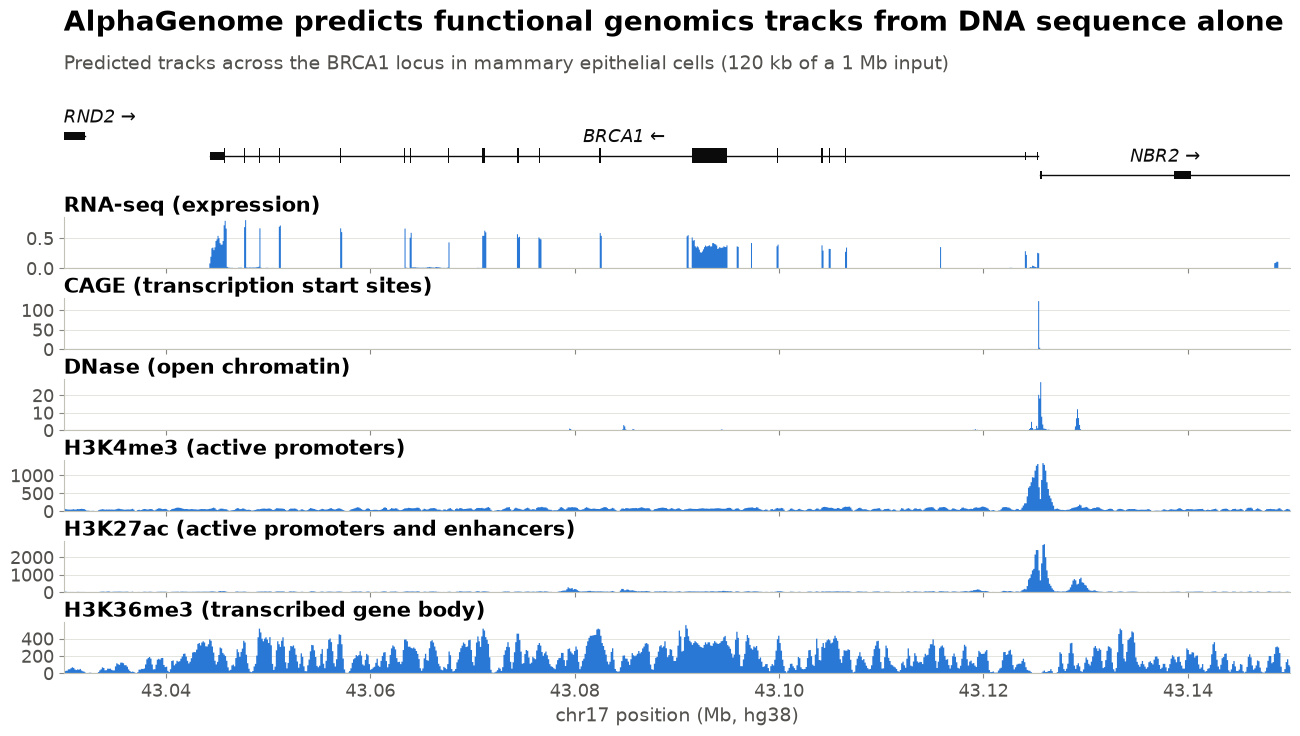

In [24]:
MODEL_OUTPUTS = {
    dna_client.OutputType.RNA_SEQ,
    dna_client.OutputType.CAGE,
    dna_client.OutputType.DNASE,
    dna_client.OutputType.CHIP_HISTONE,
}
# (panel title, output attribute, track name must contain, stranded)
MODEL_TRACKS = [
    ('RNA-seq (expression)', 'rna_seq', 'polyA', True),
    ('CAGE (transcription start sites)', 'cage', '', True),
    ('DNase (open chromatin)', 'dnase', '', False),
    ('H3K4me3 (active promoters)', 'chip_histone', 'H3K4me3', False),
    ('H3K27ac (active promoters and enhancers)', 'chip_histone', 'H3K27ac', False),
    ('H3K36me3 (transcribed gene body)', 'chip_histone', 'H3K36me3', False),
]


def get_track(td, window, contains='', strand=None):
    """x (bp) and y for one track of a TrackData, cut to `window`."""
    md = td.metadata.reset_index(drop=True)
    mask = md.name.str.contains(contains, regex=False).to_numpy(dtype=bool, copy=True)
    if strand is not None:
        mask &= (md.strand == strand).values
    i = np.flatnonzero(mask)[0]
    res = td.resolution
    i0 = max((window.start - td.interval.start) // res, 0)
    i1 = -(-(window.end - td.interval.start) // res)
    x = td.interval.start + (np.arange(i0, i1) + 0.5) * res
    return x, np.asarray(td.values[i0:i1, i], dtype=float)


def pool(x, y, signed=False, n_bins=1200):
    """Downsample to ~n_bins by keeping the most extreme value in each bin, so narrow
    1 bp peaks (CAGE, DNase) stay visible when a whole locus is drawn."""
    k = int(np.ceil(len(y) / n_bins))
    if k <= 1:
        return x, y
    n = len(y) // k * k
    xb, yb = x[:n].reshape(-1, k), y[:n].reshape(-1, k)
    pick = np.abs(yb).argmax(axis=1) if signed else yb.argmax(axis=1)
    return xb.mean(axis=1), yb[np.arange(len(yb)), pick]


def model_tracks(output, window, strand):
    """Dict of panel title -> (x, y) for the standard track set."""
    return {
        title: get_track(getattr(output, attr), window, contains, strand if stranded else None)
        for title, attr, contains, stranded in MODEL_TRACKS
    }


brca1_locus = LOCI['BRCA1']
ref_output = dna_model.predict_interval(
    interval=brca1_locus.resize(dna_client.SEQUENCE_LENGTH_1MB),
    requested_outputs=MODEL_OUTPUTS,
    ontology_terms=[ONTOLOGY],
)
tracks = model_tracks(ref_output, brca1_locus, BRIDGES.Strand['BRCA1'])

fig, axes = plt.subplots(
    len(tracks) + 1, 1, figsize=SLIDE, sharex=True,
    gridspec_kw={'height_ratios': [1.5] + [1] * len(tracks), 'hspace': 0.55,
                 'top': 0.86, 'left': 0.06, 'right': 0.98},
)
draw_genes(axes[0], brca1_locus.chromosome, brca1_locus.start, brca1_locus.end,
           only=['BRCA1', 'NBR2', 'RND2'])
for ax, (title, (x, y)) in zip(axes[1:], tracks.items()):
    x, y = pool(x, y)
    ax.fill_between(x, y, color=BLUE, lw=0, step='mid')
    style_track(ax, title)
    ax.set_ylim(0, None)
axes[-1].set_xlim(brca1_locus.start, brca1_locus.end)
format_mb(axes[-1], brca1_locus.chromosome)
headline(fig, 'AlphaGenome predicts functional genomics tracks from DNA sequence alone',
         f'Predicted tracks across the BRCA1 locus in {CELL} (120 kb of a 1 Mb input)')
save(fig, 'fig01_brca1_predicted_tracks')

## AlphaGenome Atlas helpers

The Atlas holds pre-computed scores for every possible SNV. `fetch_region` pulls all
SNVs in an interval (cached in 4 kb chunks); `max_effect_table` keeps, per position,
the substitution with the largest effect.

In [25]:
ATLAS_SCORERS = ['AVI_SCORE', 'RNA_SEQ', 'SPLICE_SITES', 'DNASE', 'CAGE', 'CHIP_HISTONE']
CHUNK = 4_000
AVI, RNA = 'AVI_SCORE:AVI_SCORE', 'RNA_SEQ:polyA plus RNA-seq'
SPLICE = 'SPLICE_SITES:max'


def tidy_atlas(result, gene):
    """One row per variant, one column per scorer track (raw score, and `|q` quantile)."""
    frames = []
    for scorer, ad in result.items():
        if ad.n_obs == 0:  # e.g. splice scores outside the gene body
            continue
        names = (ad.var['name'].str.replace(ONTOLOGY, '')
                 .str.replace('Histone ChIP-seq', '').str.strip())
        strands = ad.var['strand'].map(lambda s: '' if s == '.' else f':{s}')
        cols = [f'{scorer}:{n}{s}' for n, s in zip(names, strands)]
        df = pd.DataFrame(ad.X, columns=cols)
        if 'quantiles' in ad.layers:
            df = df.join(pd.DataFrame(ad.layers['quantiles'], columns=[c + '|q' for c in cols]))
        df['variant'] = ad.obs['variant'].astype(str).values
        if 'gene_name' in ad.obs:
            df = df[(ad.obs['gene_name'] == gene).values]
        frames.append(df.drop_duplicates('variant').set_index('variant'))
    out = pd.concat(frames, axis=1).reset_index()
    parts = out['variant'].str.extract(
        r'^(?P<chrom>[^:]+):(?P<pos>\d+):(?P<ref>[ACGTN]+)>(?P<alt>[ACGTN]+)$'
    )
    out = pd.concat([parts.astype({'pos': int}), out.drop(columns='variant')], axis=1)
    return out.sort_values(['pos', 'alt']).reset_index(drop=True)


def fetch_region(region, gene):
    """All SNVs in `region` with scores for `gene`, cached in chunks (~4.5 s per kb)."""
    cache = ATLAS_CACHE / gene
    cache.mkdir(parents=True, exist_ok=True)
    frames = []
    for start in range(region.start, region.end, CHUNK):
        chunk = genome.Interval(region.chromosome, start, min(start + CHUNK, region.end))
        path = cache / f'{chunk.chromosome}_{chunk.start}_{chunk.end}.parquet'
        if not path.exists():
            for attempt in range(5):
                try:
                    result = atlas_client.query_interval(
                        chunk, requested_scorers=ATLAS_SCORERS, ontology_terms=[ONTOLOGY],
                        gene_names=[gene], progress_bar=False,
                    )
                    break
                except Exception as e:  # transient gRPC errors
                    print('retry', chunk, type(e).__name__, str(e)[:200])
                    time.sleep(10 * (attempt + 1))
            else:
                raise RuntimeError(f'failed {chunk}')
            tidy_atlas(result, gene).to_parquet(path)
        frames.append(pd.read_parquet(path))
    df = pd.concat(frames, ignore_index=True)
    for col in ['SPLICE_SITES:donor', 'SPLICE_SITES:acceptor']:
        if col not in df:
            df[col] = np.nan
    df[SPLICE] = df[['SPLICE_SITES:donor', 'SPLICE_SITES:acceptor']].max(axis=1)
    return df


# Scores that have a direction (ALT raises or lowers the signal).
SIGNED = {RNA, 'DNASE:DNase-seq', 'CAGE:hCAGE:-', 'CAGE:hCAGE:+',
          'CHIP_HISTONE:H3K4me3', 'CHIP_HISTONE:H3K27ac'}


def max_effect_table(ism, cols=(AVI, RNA, SPLICE, 'DNASE:DNase-seq', 'CAGE:hCAGE:-', 'CAGE:hCAGE:+')):
    """Per position: score and ALT base of the maximum-effect substitution."""
    out = ism.groupby('pos').ref.first().to_frame()
    for col in cols:
        key = ism[col].abs() if col in SIGNED else ism[col]
        idx = key.fillna(-np.inf).groupby(ism.pos).idxmax()
        best = ism.loc[idx, ['pos', 'alt', col]].set_index('pos')
        out[col] = best[col]
        out[col + '|alt'] = best['alt'].where(best[col].notna())
    out[AVI + '|q'] = ism.groupby('pos')[AVI + '|q'].max()
    return out


def classify_positions(pos, gene, promoter_bp=1_000):
    """Region class of each position relative to the MANE transcript of `gene`."""
    t = BRIDGES.loc[gene]
    parts = gtf[gtf.transcript_id == t.transcript_id]

    def inside(feature):
        hit = np.zeros(len(pos), dtype=bool)
        for f in parts[parts.Feature == feature].itertuples():
            hit |= (pos > f.Start) & (pos <= f.End)
        return hit

    minus = t.Strand == '-'
    upstream = pos > t.End if minus else pos <= t.Start
    downstream = pos <= t.Start if minus else pos > t.End
    cls = np.full(len(pos), 'intron', dtype=object)
    cls[inside('exon')] = 'UTR'
    cls[inside('CDS')] = 'CDS'
    cls[upstream] = "5' flank"
    cls[upstream & (np.abs(pos - t.tss) <= promoter_bp)] = 'promoter (1 kb)'
    cls[downstream] = "3' flank"
    # Exons of neighbouring protein-coding genes are not non-coding sequence of this gene.
    other = gtf[(gtf.Feature == 'exon') & (gtf.Chromosome == t.Chromosome)
                & (gtf.gene_type == 'protein_coding') & (gtf.gene_name != gene)
                & (gtf.End > pos.min()) & (gtf.Start < pos.max())]
    other = other[['Start', 'End']].drop_duplicates()
    hit = np.zeros(len(pos), dtype=bool)
    for f in other.itertuples():
        hit |= (pos > f.Start) & (pos <= f.End)
    cls[hit & np.isin(cls, ["5' flank", "3' flank", 'intron'])] = 'other gene exon'
    return cls


REGION_ORDER = ["5' flank", 'promoter (1 kb)', 'UTR', 'CDS', 'intron', "3' flank"]

ISM = {gene: fetch_region(region, gene) for gene, region in LOCI.items()}
MAXEFF = {gene: max_effect_table(df) for gene, df in ISM.items()}
for gene, df in MAXEFF.items():
    df['region'] = classify_positions(df.index.values, gene)
{gene: f'{len(df):,} variants' for gene, df in ISM.items()}

{'BRCA1': '360,000 variants',
 'BRCA2': '336,000 variants',
 'TP53': '156,000 variants'}

## Figure 2. What does one variant do?

ALT minus REF predictions across modalities. The first example, MLH1 c.-42C>T
(chr3:36993506 C>T), is one of our concordant Seqweaver hits and a ClinVar VUS.
The second is picked automatically: the ClinVar non-coding VUS near BRCA1 with the
largest predicted effect on BRCA1 expression in the Atlas (it sits in the
polyadenylation signal).

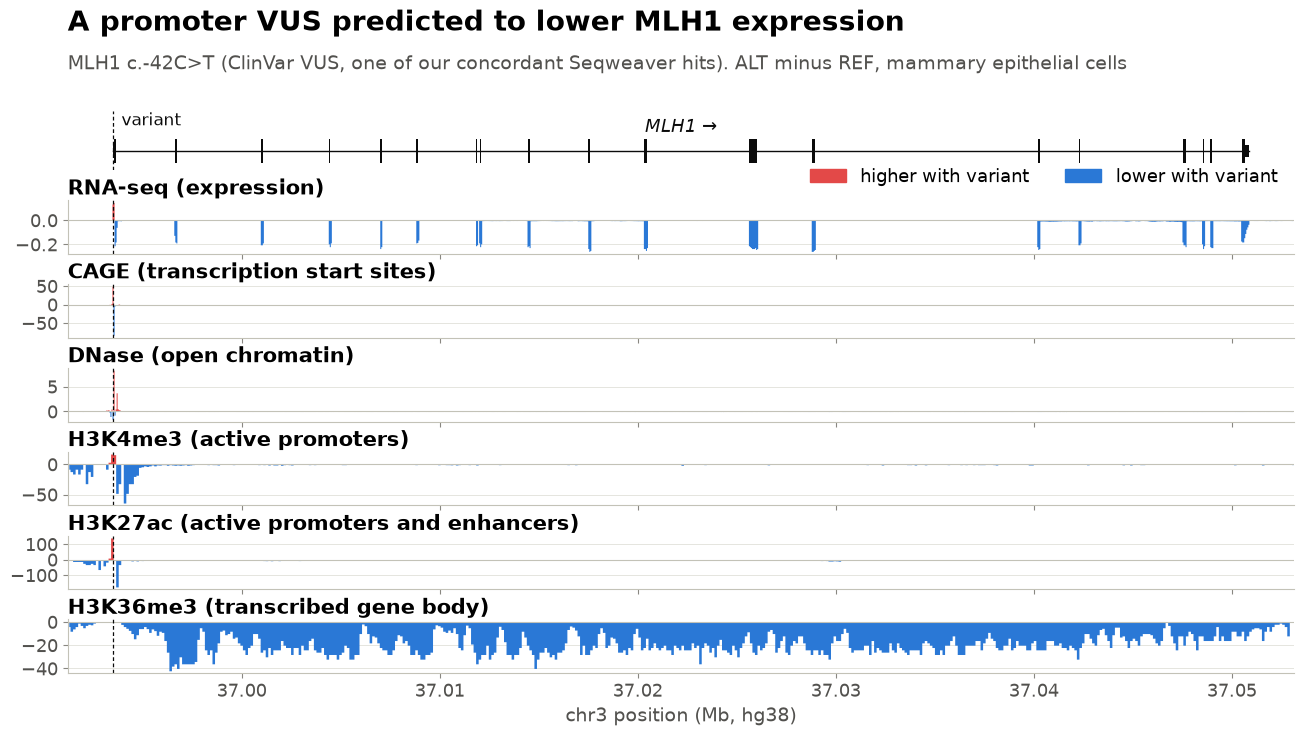

In [26]:
def figure_variant_effect(variant, gene, title, subtitle, window=None, pad=0.04):
    """ALT - REF tracks for one variant across the gene locus."""
    t = BRIDGES.loc[gene]
    if window is None:
        lo, hi = min(t.Start, variant.position), max(t.End, variant.position)
        margin = int((hi - lo) * pad)
        window = genome.Interval(t.Chromosome, lo - margin, hi + margin)
    out = dna_model.predict_variant(
        interval=variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB),
        variant=variant, requested_outputs=MODEL_OUTPUTS, ontology_terms=[ONTOLOGY],
    )
    ref, alt = (model_tracks(o, window, t.Strand) for o in (out.reference, out.alternate))
    fig, axes = plt.subplots(
        len(ref) + 1, 1, figsize=SLIDE, sharex=True,
        gridspec_kw={'height_ratios': [1.1] + [1] * len(ref), 'hspace': 0.55,
                     'top': 0.86, 'left': 0.06, 'right': 0.98},
    )
    draw_genes(axes[0], window.chromosome, window.start, window.end, only=[gene])
    for ax, name in zip(axes[1:], ref):
        x, d = pool(ref[name][0], alt[name][1] - ref[name][1], signed=True)
        ax.fill_between(x, np.clip(d, 0, None), color=UP, lw=0, step='mid')
        ax.fill_between(x, np.clip(d, None, 0), color=DOWN, lw=0, step='mid')
        style_track(ax, name)
    for ax in axes:
        ax.axvline(variant.position, color=INK, lw=0.9, ls=(0, (3, 2)))
    axes[0].annotate('variant', (variant.position, 1.25), xytext=(6, 0),
                     textcoords='offset points', fontsize=12, color=INK, va='top')
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (UP, DOWN)]
    axes[1].legend(handles, ['higher with variant', 'lower with variant'], frameon=False,
                   ncols=2, loc='lower right', bbox_to_anchor=(1, 0.95))
    axes[-1].set_xlim(window.start, window.end)
    format_mb(axes[-1], window.chromosome)
    headline(fig, title, subtitle)
    return fig


mlh1_vus = genome.Variant('chr3', 36993506, 'C', 'T', name='MLH1 c.-42C>T')
fig = figure_variant_effect(
    mlh1_vus, 'MLH1',
    'A promoter VUS predicted to lower MLH1 expression',
    f'MLH1 c.-42C>T (ClinVar VUS, one of our concordant Seqweaver hits). ALT minus REF, {CELL}',
)
save(fig, 'fig02a_variant_effect_MLH1_promoter_VUS')

In [27]:
# ClinVar SNVs in the BRIDGES genes (GRCh38).
CODING_CONSEQUENCES = {'missense_variant', 'nonsense', 'synonymous_variant',
                       'initiator_codon_variant', 'stop_lost'}
SPLICE_CONSEQUENCES = {'splice_donor_variant', 'splice_acceptor_variant'}


def clin_group(sig):
    if sig in ('Pathogenic', 'Likely_pathogenic', 'Pathogenic/Likely_pathogenic'):
        return 'P/LP'
    if sig in ('Benign', 'Likely_benign', 'Benign/Likely_benign'):
        return 'B/LB'
    if sig == 'Uncertain_significance':
        return 'VUS'
    return None


def load_clinvar():
    """P/LP and B/LB SNVs, plus non-coding VUS, in the BRIDGES genes."""
    rx = re.compile('GENEINFO=(' + '|'.join(BRIDGES_GENES) + '):')
    proc = subprocess.Popen(['zcat', str(ROOT / 'resources/clinvar.vcf.gz')],
                            stdout=subprocess.PIPE, text=True)
    rows = []
    for line in proc.stdout:
        if line[0] == '#' or 'CLNVC=single_nucleotide_variant' not in line:
            continue
        m = rx.search(line)
        if not m:
            continue
        chrom, pos, vid, ref, alt, _, _, info = line.rstrip('\n').split('\t')
        sig = re.search(r'CLNSIG=([^;]+)', info)
        mc = re.search(r'MC=([^;]+)', info)
        rev = re.search(r'CLNREVSTAT=([^;]+)', info)
        group = clin_group(sig.group(1)) if sig else None
        cons = mc.group(1).split(',')[0].split('|')[1] if mc else 'NA'
        if group is None or len(ref) != 1 or len(alt) != 1:
            continue
        if group == 'VUS' and cons in CODING_CONSEQUENCES:
            continue
        rows.append(dict(chrom='chr' + chrom, pos=int(pos), ref=ref, alt=alt, clinvar_id=vid,
                         gene=m.group(1), clin_group=group, consequence=cons,
                         review=rev.group(1) if rev else ''))
    return pd.DataFrame(rows)


CLINVAR = load_clinvar()
CLINVAR.clin_group.value_counts()

clin_group
B/LB    48668
P/LP    11970
VUS      5010
Name: count, dtype: int64

,clinvar_id,pos,ref,alt,consequence,RNA_SEQ:polyA plus RNA-seq,AVI_SCORE:AVI_SCORE,AVI_SCORE:AVI_SCORE|q
0,438907,43044315,T,A,non-coding_transcript_variant,-0.294542,0.742432,0.994246
1,1336623,43044320,T,C,non-coding_transcript_variant,-0.251325,0.626838,0.991908
176,240829,43094866,A,C,intron_variant,-0.157050,0.886845,0.995628
177,2585843,43094866,A,T,intron_variant,-0.150788,0.864248,0.995466
308,3703061,43125428,G,C,intron_variant,0.099102,0.702454,0.993664
66,865147,43057138,G,C,intron_variant,-0.093122,0.891992,0.995663
75,629239,43063385,A,T,intron_variant,-0.088804,1.208672,0.997219
303,1171499,43125357,G,A,non-coding_transcript_variant,-0.087854,0.257518,0.952562
292,4797040,43125270,C,T,splice_donor_variant,-0.083884,1.086616,0.996694
290,577927,43125269,A,G,splice_donor_variant,-0.078302,0.948890,0.996013


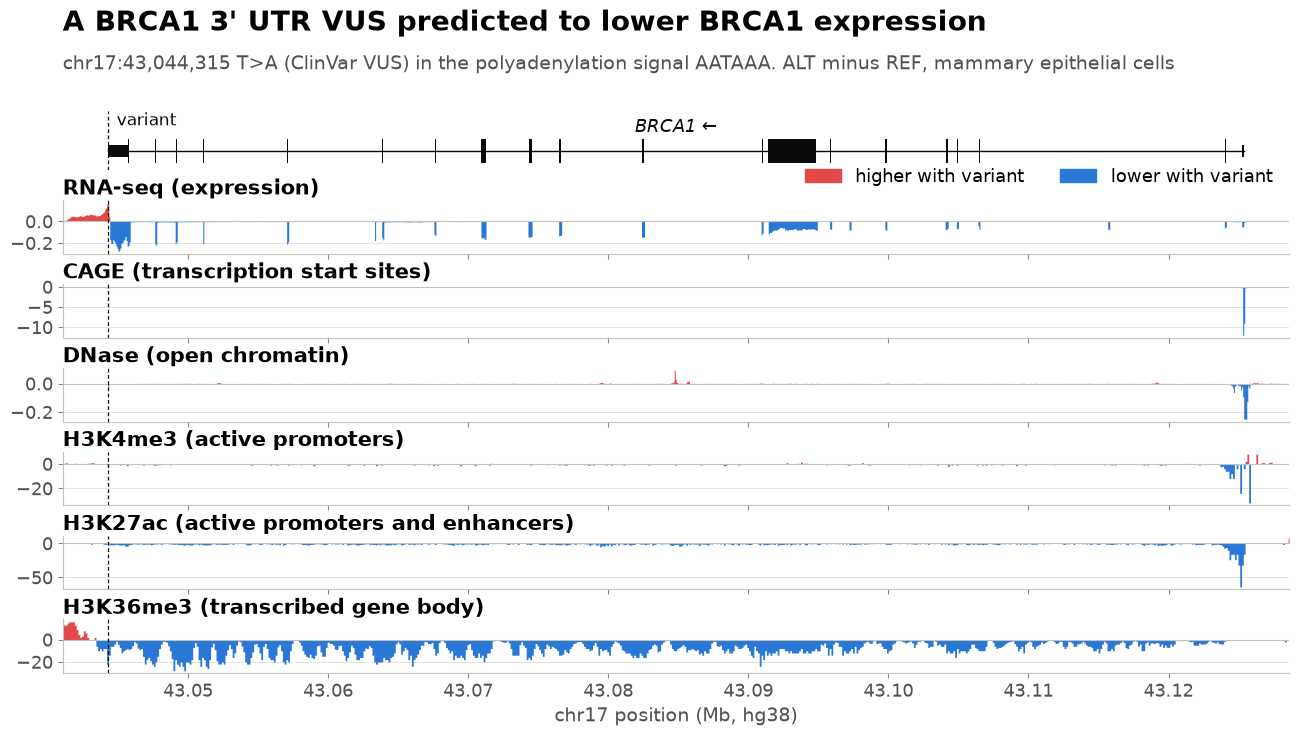

In [28]:
# BRCA1 non-coding VUS with the largest predicted effect on BRCA1 RNA in the Atlas.
brca1_vus = CLINVAR[(CLINVAR.gene == 'BRCA1') & (CLINVAR.clin_group == 'VUS')].merge(
    ISM['BRCA1'][['pos', 'ref', 'alt', RNA, RNA + '|q', AVI, AVI + '|q']],
    on=['pos', 'ref', 'alt'],
)
brca1_vus = brca1_vus.loc[brca1_vus[RNA].abs().sort_values(ascending=False).index]
display(brca1_vus.head(10)[['clinvar_id', 'pos', 'ref', 'alt', 'consequence', RNA, AVI, AVI + '|q']])

# The top hit, chr17:43044315 T>A (ClinVar 438907), is pinned here so the slide does not
# change if ClinVar is updated. It changes the BRCA1 polyadenylation signal: the
# reference + strand reads TTTATT at 43044315-43044320, i.e. AATAAA on the BRCA1 strand.
brca1_variant = genome.Variant('chr17', 43044315, 'T', 'A', name='BRCA1 3\' UTR VUS')
fig = figure_variant_effect(
    brca1_variant, 'BRCA1',
    'A BRCA1 3\' UTR VUS predicted to lower BRCA1 expression',
    f'chr17:43,044,315 T>A (ClinVar VUS) in the polyadenylation signal AATAAA. ALT minus REF, {CELL}',
)
save(fig, 'fig02b_variant_effect_BRCA1_noncoding_VUS')

## Figure 3. In silico mutagenesis of the whole BRCA1 locus

360,000 SNVs from the Atlas. Each bar is a 100 bp bin showing the most extreme
maximum-effect substitution inside it.

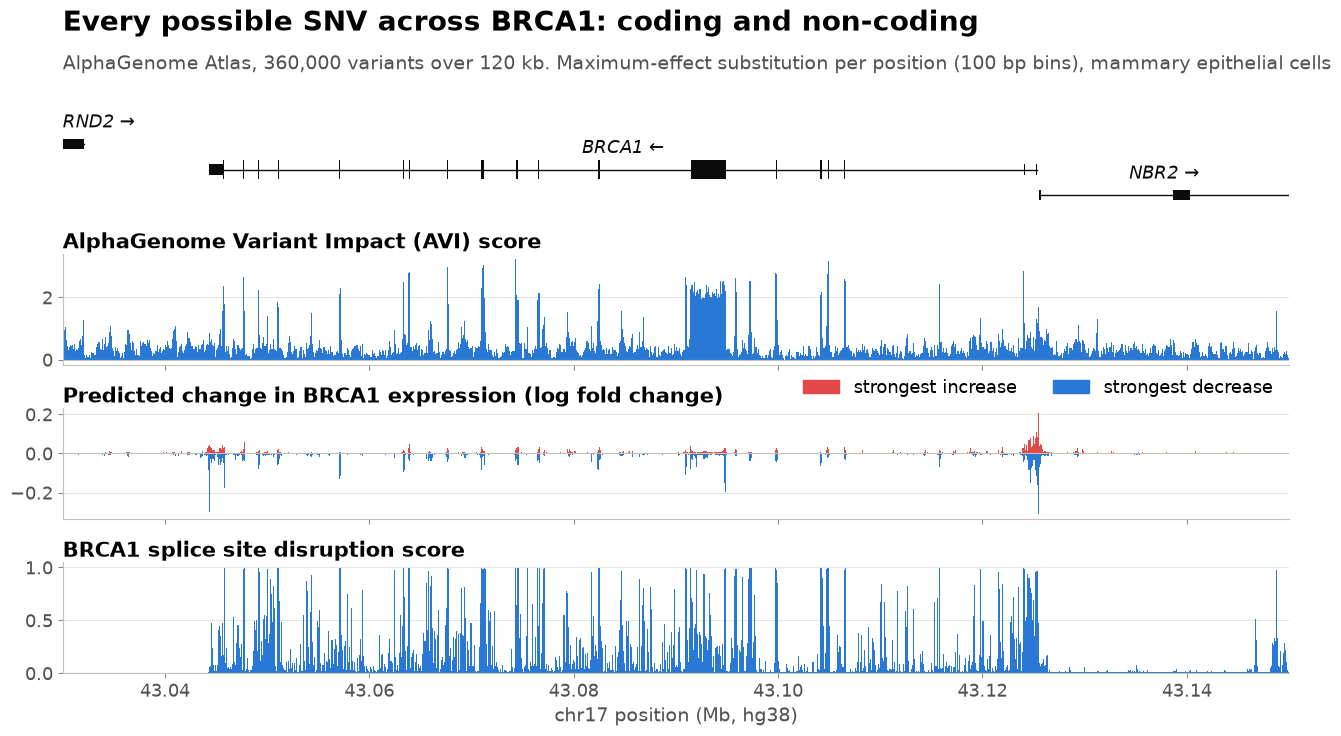

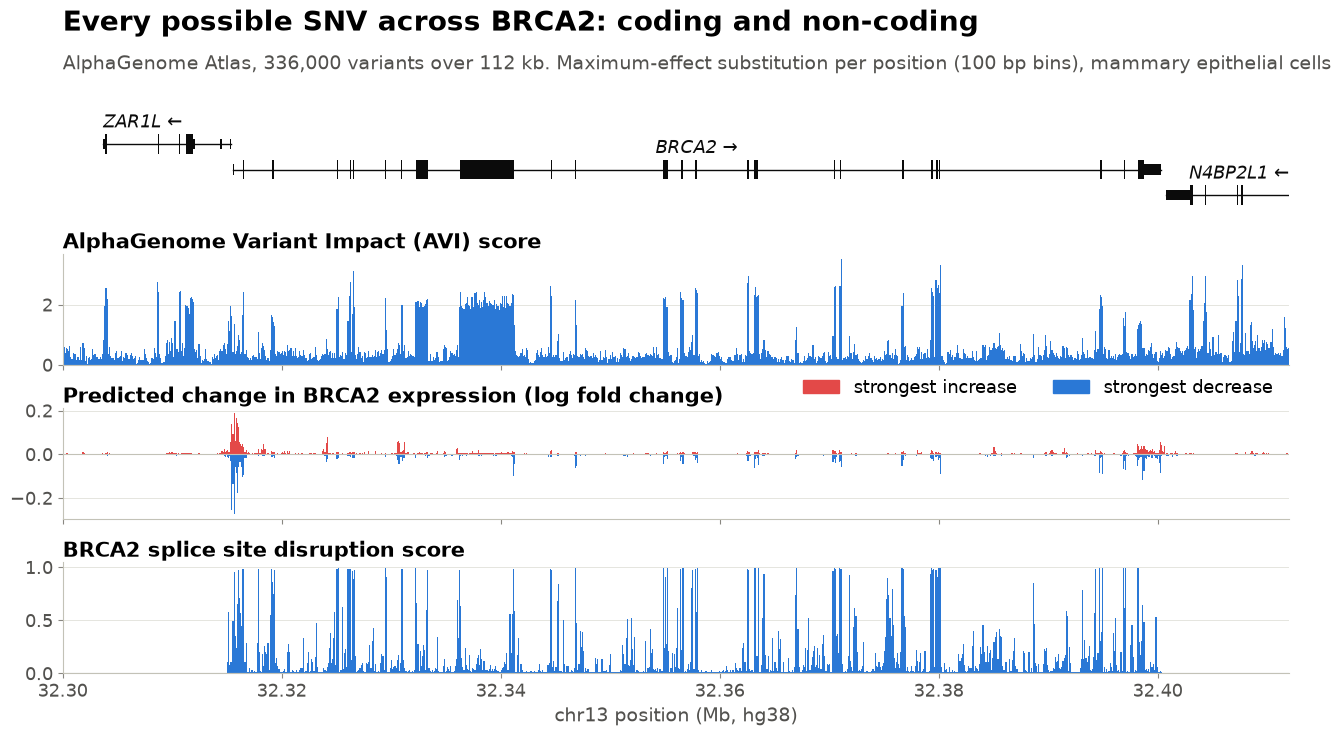

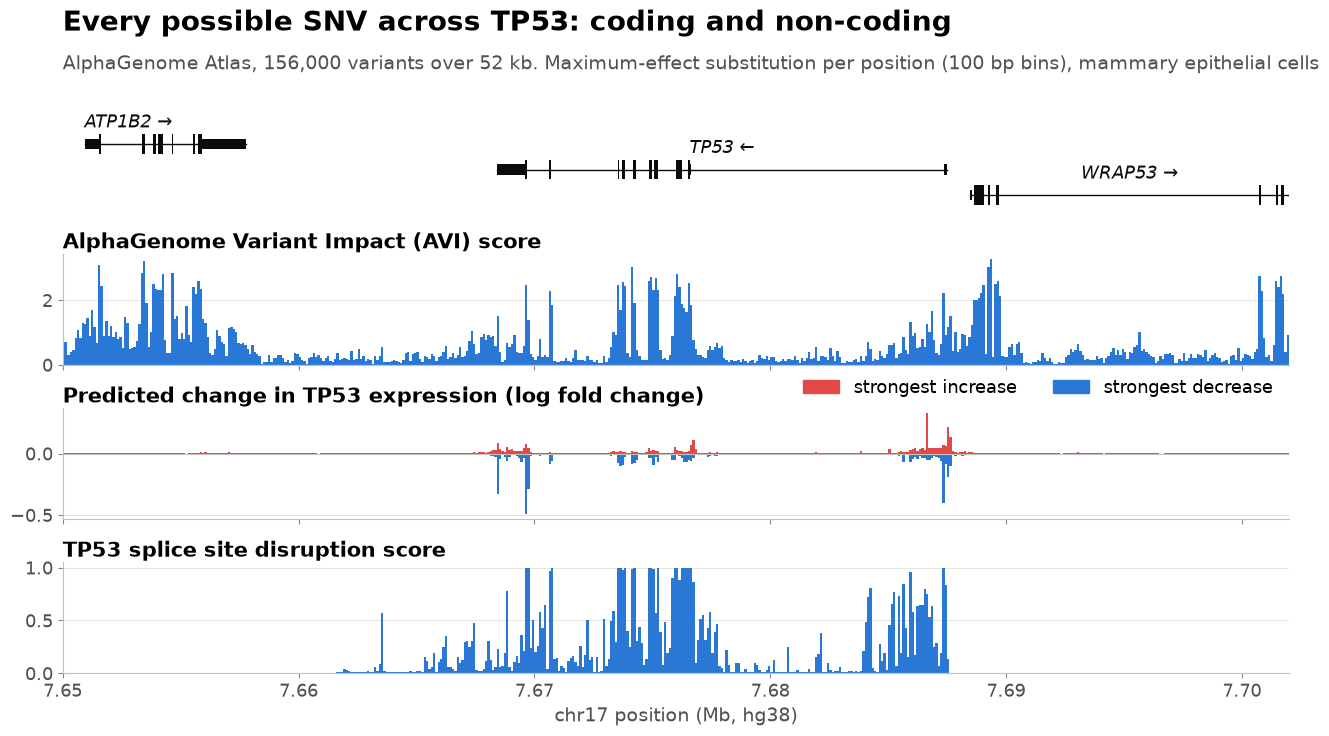

In [29]:
def figure_locus_ism(gene, bin_size=100):
    region, table = LOCI[gene], MAXEFF[gene]
    panels = [
        ('AlphaGenome Variant Impact (AVI) score', AVI),
        (f'Predicted change in {gene} expression (log fold change)', RNA),
        (f'{gene} splice site disruption score', SPLICE),
    ]
    fig, axes = plt.subplots(
        len(panels) + 1, 1, figsize=SLIDE, sharex=True,
        gridspec_kw={'height_ratios': [0.9] + [1] * len(panels), 'hspace': 0.4,
                     'top': 0.86, 'left': 0.06, 'right': 0.98},
    )
    draw_genes(axes[0], region.chromosome, region.start, region.end)
    bins = table.index // bin_size * bin_size
    for ax, (title, col) in zip(axes[1:], panels):
        grouped = table[col].groupby(bins)
        hi = grouped.max()
        if col in SIGNED:
            lo = grouped.min()
            ax.bar(hi.index, hi.clip(lower=0), width=bin_size, align='edge', color=UP, lw=0)
            ax.bar(lo.index, lo.clip(upper=0), width=bin_size, align='edge', color=DOWN, lw=0)
        else:
            ax.bar(hi.index, hi, width=bin_size, align='edge', color=BLUE, lw=0)
        style_track(ax, title)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (UP, DOWN)]
    axes[2].legend(handles, ['strongest increase', 'strongest decrease'], frameon=False,
                   ncols=2, loc='lower right', bbox_to_anchor=(1, 0.95))
    axes[-1].set_xlim(region.start, region.end)
    format_mb(axes[-1], region.chromosome)
    n = len(ISM[gene])
    headline(fig, f'Every possible SNV across {gene}: coding and non-coding',
             f'AlphaGenome Atlas, {n:,} variants over {region.width // 1000} kb. '
             f'Maximum-effect substitution per position ({bin_size} bp bins), {CELL}')
    return fig


for gene in LOCI:
    fig = figure_locus_ism(gene)
    save(fig, f'fig03_atlas_locus_ism_{gene}')

## Figure 3b. Beyond the gene: distal regulatory elements

Figure 3 only covers the gene and its flanks. Here the window is the full 1 Mb the model sees.
Mutagenising all 3 million SNVs is slow (~75 min from the Atlas), so the model first picks
candidate elements (predicted DNase peaks) and only those are mutagenised (~4 min, then cached).

,summit,dnase,acc,acc_variant,rna,rna_variant,distance,distal
28,43129146,1.882310,-2.282937,chr17:43129229:G>C,0.029485,chr17:43129256:T>A,-3782,True
26,43084800,0.547858,-2.456328,chr17:43084821:A>T,0.014257,chr17:43084814:C>A,40564,True
31,43251723,5.767038,-1.122285,chr17:43251710:A>C,0.003535,chr17:43251834:G>C,-126359,True
40,43401506,2.724831,-3.077577,chr17:43401545:G>C,-0.003416,chr17:43401387:T>G,-276142,True
47,43472004,0.610592,-2.980652,chr17:43472020:T>C,0.003104,chr17:43471852:A>T,-346640,True
32,43309967,0.922189,-3.337138,chr17:43309948:T>A,0.003063,chr17:43310020:G>T,-184603,True
17,42895355,1.550262,-3.603240,chr17:42895323:A>G,0.002966,chr17:42895207:A>G,230009,True
21,42990132,0.609017,-3.791507,chr17:42990124:G>A,-0.002948,chr17:42990110:A>T,135232,True
45,43458083,1.509941,-3.174461,chr17:43458088:G>A,-0.002944,chr17:43457949:T>C,-332719,True
36,43367943,3.784453,-0.337584,chr17:43367926:G>C,-0.002879,chr17:43368098:C>A,-242579,True


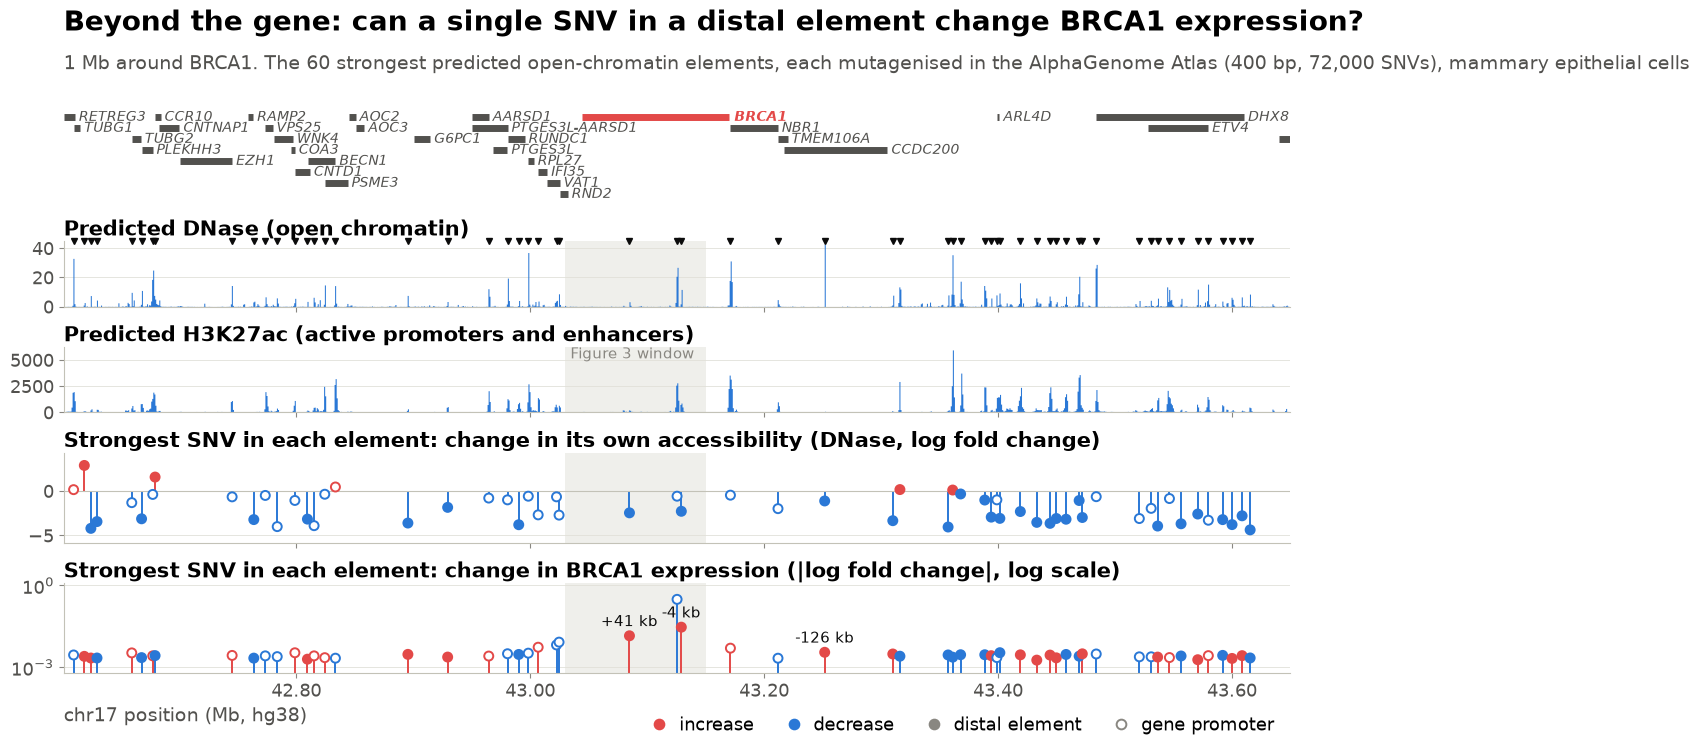

In [30]:
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d

DNASE = 'DNASE:DNase-seq'


def draw_genes_packed(ax, chrom, start, end, highlight, fontsize=10):
    """Protein-coding gene bodies packed into rows; the target gene is drawn in colour."""
    genes = gtf[(gtf.Feature == 'gene') & (gtf.Chromosome == chrom) & (gtf.End > start)
                & (gtf.Start < end) & (gtf.gene_type == 'protein_coding')].sort_values('Start')
    pad, row_end = (end - start) * 0.06, []  # room for the label right of each gene
    for g in genes.itertuples():
        lo, hi = max(g.Start, start), min(g.End, end)
        row = next((i for i, e in enumerate(row_end) if lo > e), len(row_end))
        row_end[row:row + 1] = [hi + pad]
        color = UP if g.gene_name == highlight else SECONDARY
        ax.plot([lo, hi], [-row, -row], color=color, lw=5, solid_capstyle='butt')
        ax.text(hi, -row, f' {g.gene_name}', ha='left', va='center', fontsize=fontsize, color=color,
                style='italic', weight='bold' if g.gene_name == highlight else 'normal', clip_on=True)
    ax.set_ylim(-len(row_end) + 0.4, 0.6)
    ax.set_yticks([])
    for side in ('left', 'bottom'):
        ax.spines[side].set_visible(False)
    ax.tick_params(bottom=False)


def call_elements(output, window, n=60, min_distance=2_000, smooth=150):
    """Summits of the n strongest predicted DNase peaks in `window`."""
    x, y = get_track(output.dnase, window)
    y = uniform_filter1d(y, smooth)
    peaks, props = find_peaks(y, distance=min_distance, height=0)
    keep = peaks[np.argsort(props['peak_heights'])[::-1][:n]]
    return pd.DataFrame({'summit': x[keep].astype(int), 'dnase': y[keep]}).sort_values('summit')


def element_ism(elements, gene, chrom, width=400):
    """Atlas mutagenesis of each element: its strongest SNV for local accessibility and for
    expression of `gene`."""
    rows = []
    for e in elements.itertuples():
        df = fetch_region(genome.Interval(chrom, e.summit - width // 2, e.summit + width // 2), gene)
        row = dict(summit=e.summit, dnase=e.dnase)
        for key, col in [('acc', DNASE), ('rna', RNA)]:
            best = df.loc[df[col].abs().idxmax()]
            row.update({key: best[col], f'{key}_variant': f'{chrom}:{best.pos}:{best.ref}>{best.alt}'})
        rows.append(row)
    return pd.DataFrame(rows)


def figure_distal_ism(gene, n_elements=60, promoter_bp=2_000, n_label=3):
    t = BRIDGES.loc[gene]
    window = genome.Interval(t.Chromosome, t.tss, t.tss).resize(dna_client.SEQUENCE_LENGTH_1MB)
    output = dna_model.predict_interval(
        interval=window, ontology_terms=[ONTOLOGY],
        requested_outputs={dna_client.OutputType.DNASE, dna_client.OutputType.CHIP_HISTONE},
    )
    elements = element_ism(call_elements(output, window, n_elements), gene, t.Chromosome)
    # Distance to the TSS in the direction of transcription (negative = upstream).
    elements['distance'] = (elements.summit - t.tss) * (-1 if t.Strand == '-' else 1)
    # Any protein-coding TSS counts as a promoter; everything else is a distal element.
    tss = gtf[(gtf.Feature == 'transcript') & (gtf.Chromosome == t.Chromosome)
              & (gtf.gene_type == 'protein_coding')]
    tss = np.where(tss.Strand == '-', tss.End, tss.Start + 1)
    elements['distal'] = np.abs(elements.summit.values[:, None] - tss[None, :]).min(axis=1) > promoter_bp

    fig, axes = plt.subplots(
        5, 1, figsize=SLIDE, sharex=True,
        gridspec_kw={'height_ratios': [1.1, 0.8, 0.8, 1.1, 1.1], 'hspace': 0.5,
                     'top': 0.86, 'left': 0.06, 'right': 0.98},
    )
    draw_genes_packed(axes[0], window.chromosome, window.start, window.end, gene)
    for ax, title, (x, y) in [
        (axes[1], 'Predicted DNase (open chromatin)', get_track(output.dnase, window)),
        (axes[2], 'Predicted H3K27ac (active promoters and enhancers)',
         get_track(output.chip_histone, window, 'H3K27ac')),
    ]:
        x, y = pool(x, y)
        ax.fill_between(x, y, color=BLUE, lw=0, step='mid')
        style_track(ax, title)
        ax.set_ylim(0, None)
    axes[1].plot(elements.summit, np.full(len(elements), axes[1].get_ylim()[1]), 'v', ms=4,
                 color=INK, clip_on=False)
    # Promoter elements are drawn hollow, distal elements filled.
    def lollipops(ax, y, base):
        colors = np.where(elements[key] > 0, UP, DOWN)
        ax.vlines(elements.summit, base, y, colors=colors, lw=1.4)
        ax.scatter(elements.summit, y, s=42, edgecolors=colors, lw=1.4, zorder=3,
                   c=np.where(elements.distal, colors, 'white'))

    key = 'acc'
    lollipops(axes[3], elements.acc, 0)
    style_track(axes[3], 'Strongest SNV in each element: change in its own accessibility (DNase, log fold change)')
    axes[3].margins(y=0.2)
    # Expression effects span orders of magnitude between promoter and distal elements.
    key, size = 'rna', elements.rna.abs()
    floor = size.min() / 3
    lollipops(axes[4], size, floor)
    axes[4].set_yscale('log')
    axes[4].set_ylim(floor, size.max() * 4)
    axes[4].set_title(f'Strongest SNV in each element: change in {gene} expression (|log fold change|, log scale)', pad=4)
    axes[4].grid(axis='y', color=GRID, lw=0.6)
    axes[4].set_axisbelow(True)
    top = elements[elements.distal].sort_values('rna', key=np.abs, ascending=False).head(n_label)
    for e in top.itertuples():
        axes[4].annotate(f'{e.distance / 1e3:+.0f} kb', (e.summit, abs(e.rna)), xytext=(0, 7),
                         textcoords='offset points', fontsize=11, color=INK, ha='center')
    if gene in LOCI:  # the window drawn in Figure 3
        for ax in axes[1:]:
            ax.axvspan(LOCI[gene].start, LOCI[gene].end, color=GRID, alpha=0.5, lw=0, zorder=0)
        axes[2].text(LOCI[gene].start, axes[2].get_ylim()[1], ' Figure 3 window', fontsize=11,
                     color=MUTED, va='top')
    handles = [plt.Line2D([], [], marker='o', ls='', ms=7, mec=ec, mfc=fc, mew=1.4)
               for ec, fc in [(UP, UP), (DOWN, DOWN), (MUTED, MUTED), (MUTED, 'white')]]
    axes[-1].legend(handles, ['increase', 'decrease', 'distal element', 'gene promoter'], frameon=False,
                    ncols=4, loc='upper right', bbox_to_anchor=(1, -0.3), handletextpad=0.1,
                    columnspacing=1.2)
    axes[-1].set_xlim(window.start, window.end)
    format_mb(axes[-1], window.chromosome)
    axes[-1].set_xlabel(axes[-1].get_xlabel(), loc='left')  # leaves room for the legend
    headline(fig, f'Beyond the gene: can a single SNV in a distal element change {gene} expression?',
             f'1 Mb around {gene}. The {len(elements)} strongest predicted open-chromatin elements, each '
             f'mutagenised in the AlphaGenome Atlas (400 bp, {len(elements) * 1200:,} SNVs), {CELL}')
    return fig, elements


fig, DISTAL = figure_distal_ism('BRCA1')
save(fig, 'fig03b_atlas_distal_elements_BRCA1')
DISTAL[DISTAL.distal].sort_values('rna', key=np.abs, ascending=False).head(10)

## Figure 4. Base resolution at the BRCA1 core promoter

One bar per base, coloured by the ALT base with the largest effect.

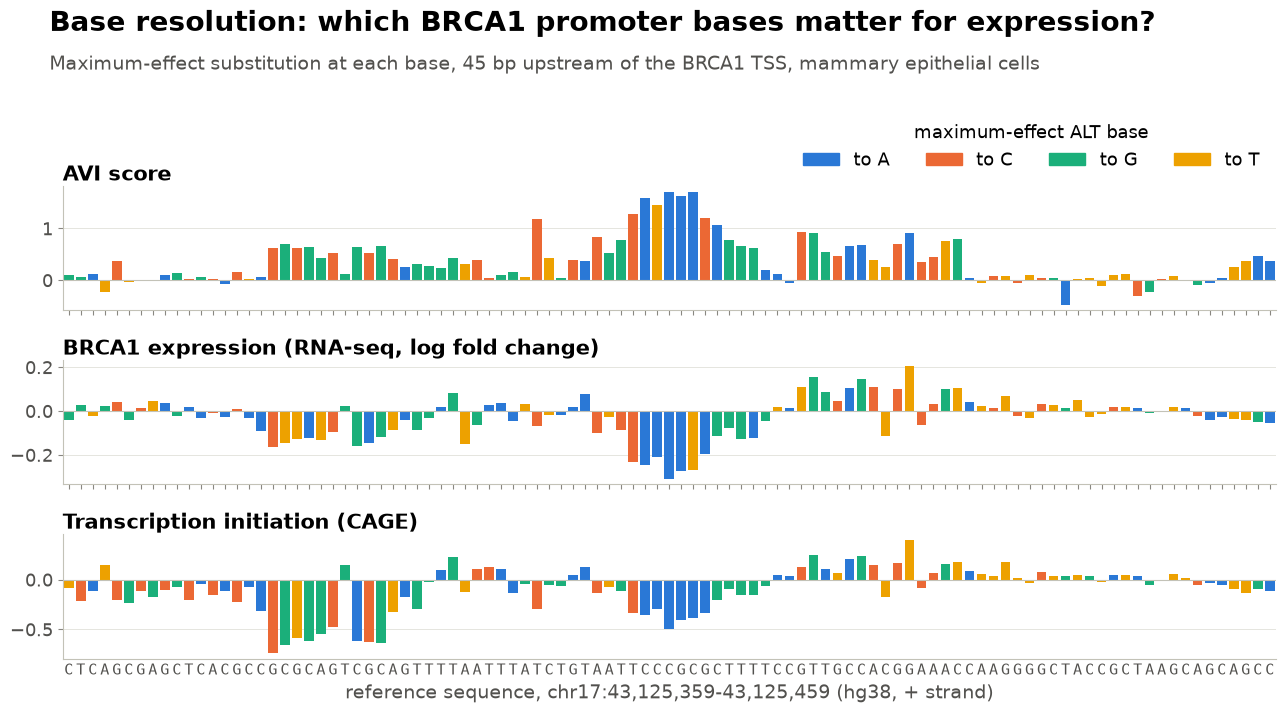

In [31]:
def figure_base_resolution(gene, center, width=100, title=None, subtitle=None):
    table = MAXEFF[gene]
    cage = 'CAGE:hCAGE:-' if BRIDGES.Strand[gene] == '-' else 'CAGE:hCAGE:+'
    panels = [
        ('AVI score', AVI),
        (f'{gene} expression (RNA-seq, log fold change)', RNA),
        ('Transcription initiation (CAGE)', cage),
    ]
    start, end = center - width // 2, center + width // 2
    win = table.loc[start:end]
    fig, axes = plt.subplots(
        len(panels), 1, figsize=SLIDE, sharex=True,
        gridspec_kw={'hspace': 0.4, 'top': 0.76, 'left': 0.07, 'right': 0.98, 'bottom': 0.13},
    )
    for ax, (name, col) in zip(axes, panels):
        colors = win[col + '|alt'].map(NUC_COLORS).fillna(GRID)
        ax.bar(win.index, win[col].fillna(0), width=0.8, color=colors, lw=0)
        style_track(ax, name)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in NUC_COLORS.values()]
    axes[0].legend(handles, [f'to {n}' for n in NUC_COLORS], frameon=False, ncols=4,
                   loc='lower right', bbox_to_anchor=(1, 1.0), title='maximum-effect ALT base',
                   title_fontsize=13)
    axes[-1].set_xlim(start - 0.5, end + 0.5)
    axes[-1].set_xticks(win.index, win.ref, fontsize=10.5, family='monospace')
    axes[-1].tick_params(axis='x', length=0)
    axes[-1].set_xlabel(f'reference sequence, {LOCI[gene].chromosome}:{start:,}-{end:,} (hg38, + strand)')
    headline(fig, title or f'{gene} at base resolution', subtitle)
    return fig


brca1 = MAXEFF['BRCA1']
top_promoter = brca1.loc[brca1.region == 'promoter (1 kb)', RNA].abs().idxmax()
fig = figure_base_resolution(
    'BRCA1', top_promoter, width=100,
    title='Base resolution: which BRCA1 promoter bases matter for expression?',
    subtitle=(f'Maximum-effect substitution at each base, '
              f'{abs(top_promoter - BRIDGES.tss["BRCA1"])} bp upstream of the BRCA1 TSS, {CELL}'),
)
save(fig, 'fig04_atlas_BRCA1_promoter_base_resolution')

## Figure 5. Promoter mutagenesis across all 34 BRIDGES genes

For each gene, all SNVs from 1.5 kb upstream to 0.5 kb downstream of the MANE TSS
(204,000 variants in total), scored for their effect on that gene's own expression.

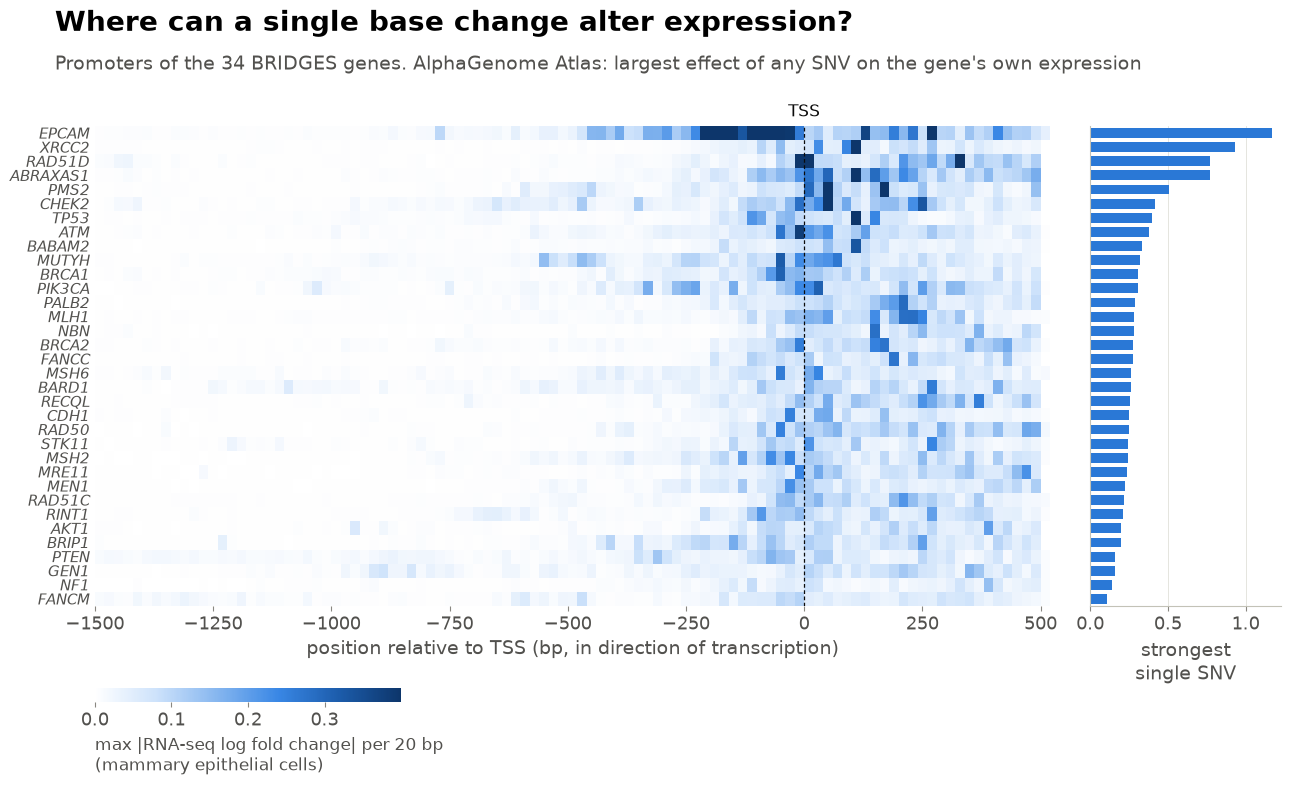

In [32]:
UP_BP, DOWN_BP, BIN = 1500, 500, 20


def promoter_profile(gene):
    """Max |RNA log fold change| per position, oriented 5'->3' relative to the TSS."""
    t = BRIDGES.loc[gene]
    minus = t.Strand == '-'
    lo, hi = (t.tss - DOWN_BP, t.tss + UP_BP) if minus else (t.tss - UP_BP, t.tss + DOWN_BP)
    df = fetch_region(genome.Interval(t.Chromosome, lo, hi), gene)
    rel = (t.tss - df.pos) if minus else (df.pos - t.tss)
    return df[RNA].abs().groupby(rel).max()


PROMOTERS = pd.DataFrame({g: promoter_profile(g) for g in BRIDGES_GENES}).T
bins = PROMOTERS.columns // BIN * BIN
binned = PROMOTERS.T.groupby(bins).max().T
binned = binned.loc[binned.max(axis=1).sort_values(ascending=False).index]

fig, (ax, ax_bar) = plt.subplots(
    1, 2, figsize=SLIDE, sharey=True,
    gridspec_kw={'width_ratios': [5, 1], 'wspace': 0.07, 'top': 0.84, 'left': 0.09,
                 'right': 0.98, 'bottom': 0.2},
)
vmax = np.nanquantile(binned.values, 0.995)
im = ax.imshow(binned.values, aspect='auto', cmap=SEQUENTIAL, vmin=0, vmax=vmax,
               extent=[binned.columns[0], binned.columns[-1] + BIN, len(binned), 0],
               interpolation='nearest')
ax.axvline(0, color=INK, lw=0.9, ls=(0, (3, 2)))
ax.set_yticks(np.arange(len(binned)) + 0.5, binned.index, fontsize=10.5, style='italic')
ax.tick_params(axis='y', length=0)
ax.set_xlabel('position relative to TSS (bp, in direction of transcription)')
ax.text(0, -0.4, 'TSS', ha='center', va='bottom', fontsize=12, color=INK)
for side in ('left', 'bottom'):
    ax.spines[side].set_visible(False)
cax = ax.inset_axes([0.0, -0.2, 0.32, 0.03])
cbar = fig.colorbar(im, cax=cax, orientation='horizontal')
cbar.set_label(f'max |RNA-seq log fold change| per {BIN} bp\n({CELL})', fontsize=12, loc='left')
cbar.outline.set_visible(False)
ax_bar.barh(np.arange(len(binned)) + 0.5, binned.max(axis=1), height=0.7, color=BLUE)
ax_bar.set_xlabel('strongest\nsingle SNV')
ax_bar.grid(axis='x', color=GRID, lw=0.6)
ax_bar.set_axisbelow(True)
ax_bar.tick_params(axis='y', length=0)
headline(fig, 'Where can a single base change alter expression?',
         'Promoters of the 34 BRIDGES genes. AlphaGenome Atlas: largest effect of any SNV on the gene\'s own expression')
save(fig, 'fig05_promoter_ism_34_genes')

## Figure 6. Coding vs non-coding impact

Share of positions where the best substitution has an AVI score above the 99th
percentile of the Atlas score distribution (quantile > 0.99).

,BRCA1,BRCA2,TP53
region,,,
5' flank,0.5,0.7,0.5
promoter (1 kb),7.1,3.4,8.0
UTR,2.5,0.4,2.1
CDS,33.6,29.8,54.8
intron,0.8,0.6,0.9
3' flank,1.7,2.3,3.2


,BRCA1,BRCA2,TP53
region,,,
5' flank,23636,13015,11232
promoter (1 kb),1000,1000,1000
UTR,1499,1700,1333
CDS,5589,10254,1179
intron,73982,72807,15328
3' flank,12253,7603,15031


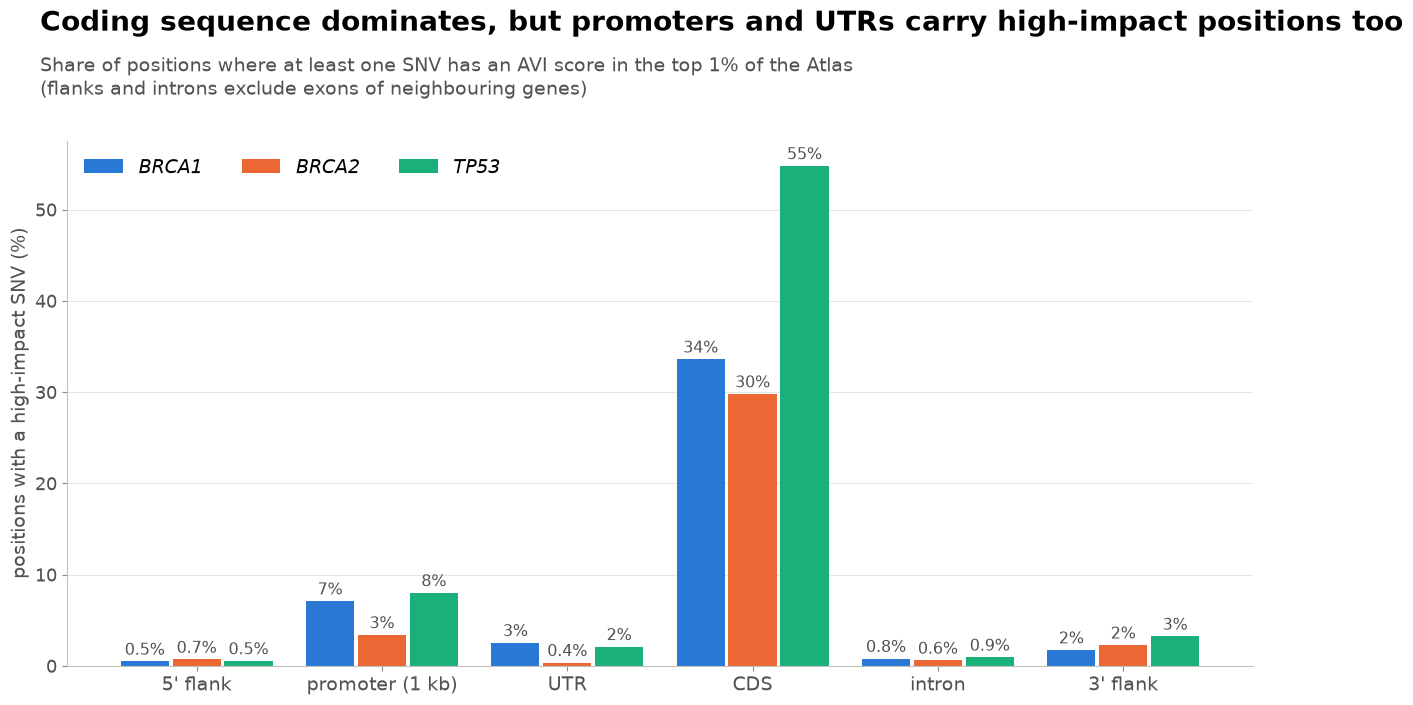

In [33]:
share = pd.DataFrame({
    gene: (df[AVI + '|q'] > 0.99).groupby(df.region).mean().reindex(REGION_ORDER)
    for gene, df in MAXEFF.items()
}) * 100
counts = pd.DataFrame({g: df.region.value_counts().reindex(REGION_ORDER) for g, df in MAXEFF.items()})
display(share.round(1), counts)

fig, ax = plt.subplots(figsize=SLIDE, gridspec_kw={'top': 0.82, 'left': 0.08, 'right': 0.97, 'bottom': 0.12})
width = 0.26
for i, (gene, color) in enumerate(zip(share.columns, SERIES)):
    x = np.arange(len(share)) + (i - 1) * (width + 0.02)
    bars = ax.bar(x, share[gene], width=width, color=color, label=gene)
    ax.bar_label(bars, labels=[f'{v:.0f}%' if v >= 1 else f'{v:.1f}%' for v in share[gene]],
                 fontsize=11.5, color=SECONDARY, padding=2)
ax.set_xticks(np.arange(len(share)), share.index, fontsize=14)
ax.set_ylabel('positions with a high-impact SNV (%)')
ax.grid(axis='y', color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncols=3, loc='upper left', prop={'style': 'italic', 'size': 14})
headline(fig, 'Coding sequence dominates, but promoters and UTRs carry high-impact positions too',
         'Share of positions where at least one SNV has an AVI score in the top 1% of the Atlas\n'
         '(flanks and introns exclude exons of neighbouring genes)')
save(fig, 'fig06_coding_vs_noncoding')

## Figure 7. Our Seqweaver variants against AlphaGenome

All BRIDGES variants scored by Seqweaver (GRCh37 ids) are lifted to hg38 and looked up
in the Atlas: AVI score plus the predicted RNA-seq effect on the nearest BRIDGES gene.

In [34]:
lo = LiftOver('hg19', 'hg38')


def to_variant(snp):
    """hg19 'chrom_pos_ref_alt' (1-based) -> hg38 Variant, or None if it does not lift."""
    c, p, ref, alt = snp.split('_')
    hit = lo.convert_coordinate(f'chr{c}', int(p) - 1)
    if not hit or hit[0][0] != f'chr{c}' or hit[0][2] != '+':
        return None
    return genome.Variant(f'chr{c}', hit[0][1] + 1, ref, alt, name=snp)


def atlas_scores_for_variants(variants, path, workers=16):
    """AVI score and per-gene RNA-seq effect for a list of variants (cached)."""
    if path.exists():
        return pd.read_parquet(path)

    def one(v):
        for attempt in range(4):
            try:
                r = atlas_client.query_variant(
                    v, requested_scorers=['AVI_SCORE', 'RNA_SEQ'],
                    ontology_terms=[ONTOLOGY], gene_names=BRIDGES_GENES,
                )
                break
            except ValueError:  # reference mismatch or not in the Atlas
                return []
            except Exception:
                time.sleep(3 * (attempt + 1))
        else:
            return []
        avi = r['AVI_SCORE']
        base = dict(SNP=v.name, chrom=v.chromosome, pos=v.position,
                    AVI=float(avi.X[0, 0]), AVI_quantile=float(avi.layers['quantiles'][0, 0]))
        rna = r.get('RNA_SEQ')
        if rna is None or rna.n_obs == 0:
            return [base]
        j = np.flatnonzero(rna.var['name'].str.contains('polyA').values)[0]
        return [dict(base, gene=g, rna_lfc=float(rna.X[i, j]),
                     rna_quantile=float(rna.layers['quantiles'][i, j]))
                for i, g in enumerate(rna.obs['gene_name'])]

    with concurrent.futures.ThreadPoolExecutor(workers) as ex:
        rows = [row for res in ex.map(one, variants) for row in res]
    df = pd.DataFrame(rows)
    df.to_parquet(path)
    return df


Z_SCORES = pd.read_csv(ROOT / 'data/eirik/Seqweaver_bridges__breast.csv', index_col=0)
epithelial = [c for c in Z_SCORES if c.startswith(('Lumsec', 'LummHR')) or c == 'basal']
seqweaver = Z_SCORES[epithelial].mean(axis=1).rename('seqweaver_mean_z')
CONCORDANT = pd.read_csv('concordant_variants_breast_epithelial.csv')

variants = [v for v in map(to_variant, Z_SCORES.index) if v is not None]
scores = atlas_scores_for_variants(variants, ATLAS_CACHE / 'bridges_seqweaver_variants.parquet')

# Keep, per SNP, the nearest BRIDGES gene (by TSS).
scores = scores.dropna(subset=['gene']).copy()
scores['dist'] = (scores.pos - scores.gene.map(BRIDGES.tss)).abs()
VARIANTS = (scores.sort_values('dist').drop_duplicates('SNP').set_index('SNP')
            .join(seqweaver).assign(concordant=lambda d: d.index.isin(CONCORDANT.SNP)))
print(f'{len(VARIANTS):,} of {len(Z_SCORES):,} Seqweaver variants scored in the Atlas')
VARIANTS.head()

10,065 of 10,066 Seqweaver variants scored in the Atlas


,chrom,pos,AVI,AVI_quantile,gene,rna_lfc,rna_quantile,dist,seqweaver_mean_z,concordant
SNP,,,,,,,,,,
2_17935405_G_T,chr2,17754138,0.808614,0.994995,GEN1,-0.031575,-0.999581,0,-1.830848,True
17_56769964_T_C,chr17,58692603,0.121951,0.871657,RAD51C,-0.036553,-0.999658,1,-10.781046,True
2_47630296_C_T,chr2,47403157,0.129479,0.878937,MSH2,-0.039087,-0.999680,1,3.576125,False
2_47630294_C_T,chr2,47403155,-0.046245,0.175280,MSH2,-0.024554,-0.999412,1,0.530033,False
13_32889647_A_C,chr13,32315510,0.045696,0.740691,BRCA2,-0.023208,-0.999349,2,5.216285,False


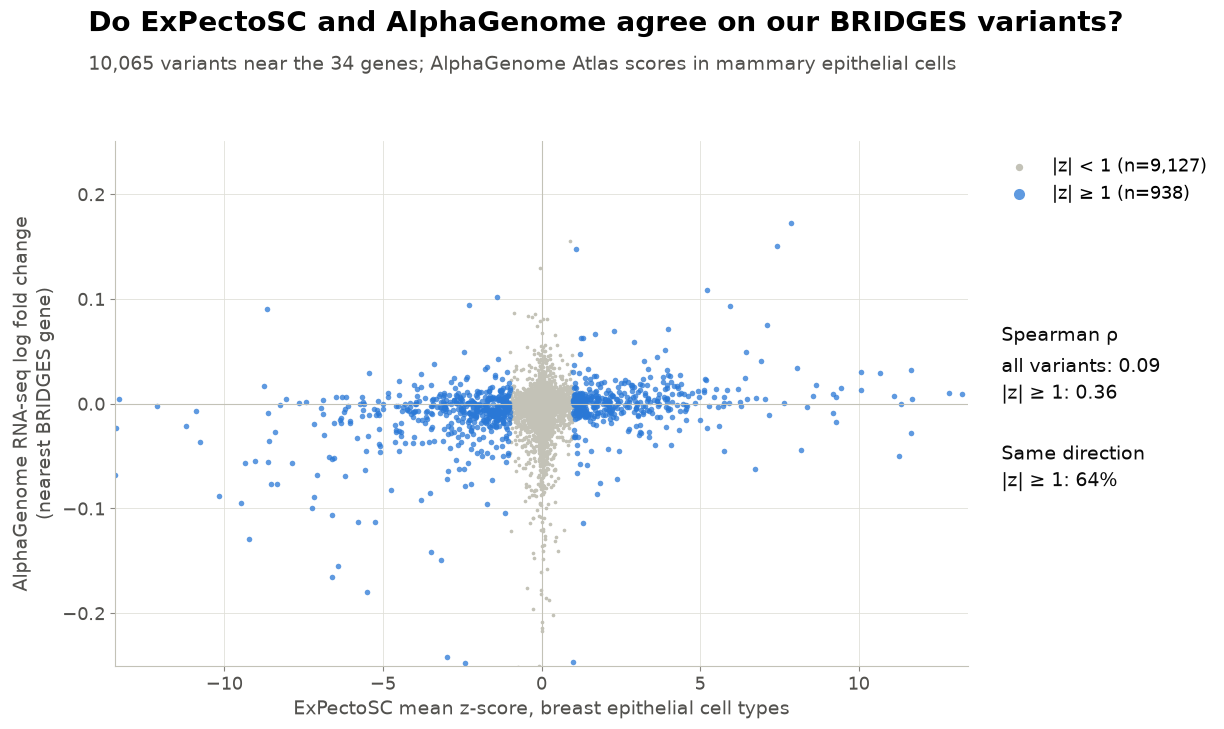

In [35]:
x, y = VARIANTS.seqweaver_mean_z, VARIANTS.rna_lfc
rho_all = x.corr(y, method='spearman')
strong = x.abs() >= 1
rho_strong = x[strong].corr(y[strong], method='spearman')
same_sign = (np.sign(x[strong]) == np.sign(y[strong])).mean()

fig, ax = plt.subplots(figsize=SLIDE, gridspec_kw={'top': 0.82, 'left': 0.08, 'right': 0.72, 'bottom': 0.12})
lim_x, lim_y = np.nanquantile(x.abs(), 0.999), np.nanquantile(y.abs(), 0.999)
ax.scatter(x[~strong], y[~strong], s=7, color=AXIS, lw=0, label=f'|z| < 1 (n={int((~strong).sum()):,})')
ax.scatter(x[strong], y[strong], s=16, color=BLUE, lw=0, alpha=0.75,
           label=f'|z| ≥ 1 (n={int(strong.sum()):,})')
ax.axhline(0, color=AXIS, lw=0.8)
ax.axvline(0, color=AXIS, lw=0.8)
ax.set_xlim(-lim_x, lim_x)
ax.set_ylim(-lim_y, lim_y)
ax.set_xlabel('ExPectoSC mean z-score, breast epithelial cell types')
ax.set_ylabel('AlphaGenome RNA-seq log fold change\n(nearest BRIDGES gene)')
ax.grid(color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.02, 1.0), markerscale=2)
fig.text(0.745, 0.58,
         f'Spearman ρ\nall variants: {rho_all:.2f}\n|z| ≥ 1: {rho_strong:.2f}\n\n'
         f'Same direction\n|z| ≥ 1: {same_sign:.0%}',
         fontsize=14, color=INK, va='top', linespacing=1.5)
headline(fig, 'Do ExPectoSC and AlphaGenome agree on our BRIDGES variants?',
         f'{len(VARIANTS):,} variants near the 34 genes; AlphaGenome Atlas scores in {CELL}')
save(fig, 'fig07_expectosc_vs_alphagenome')

## Figure 8. Top candidate regulatory variants

Variants where both models predict a strong effect in the same direction, ranked by the
AlphaGenome effect on the gene.

,gene,chrom,pos,rna_lfc,rna_quantile,AVI,AVI_quantile,seqweaver_mean_z,concordant
SNP,,,,,,,,,
7_6048626_A_C,PMS2,chr7,6008995,-0.496953,-0.999997,1.759213,0.999466,-8.006679,True
16_23652431_C_T,PALB2,chr16,23641110,-0.278825,-0.999989,1.715807,0.999410,-2.486074,True
13_32889809_G_T,BRCA2,chr13,32315672,-0.263697,-0.999988,1.338441,0.997775,-1.779801,True
13_32889806_T_C,BRCA2,chr13,32315669,-0.260662,-0.999988,1.190090,0.997142,-1.568009,True
7_6048629_T_C,PMS2,chr7,6008998,-0.253854,-0.999987,0.745839,0.994290,-4.952852,True
16_23652430_C_T,PALB2,chr16,23641109,-0.247214,-0.999986,1.579905,0.999055,-2.410463,True
2_215674135_C_A,BARD1,chr2,214809411,-0.241590,-0.999985,1.688954,0.999370,-2.973491,True
5_131893146_G_T,RAD50,chr5,132557454,-0.180057,-0.999975,2.203119,0.999808,-5.493921,True
16_23652461_C_A,PALB2,chr16,23641140,0.172756,0.999978,1.271534,0.997481,7.867455,False


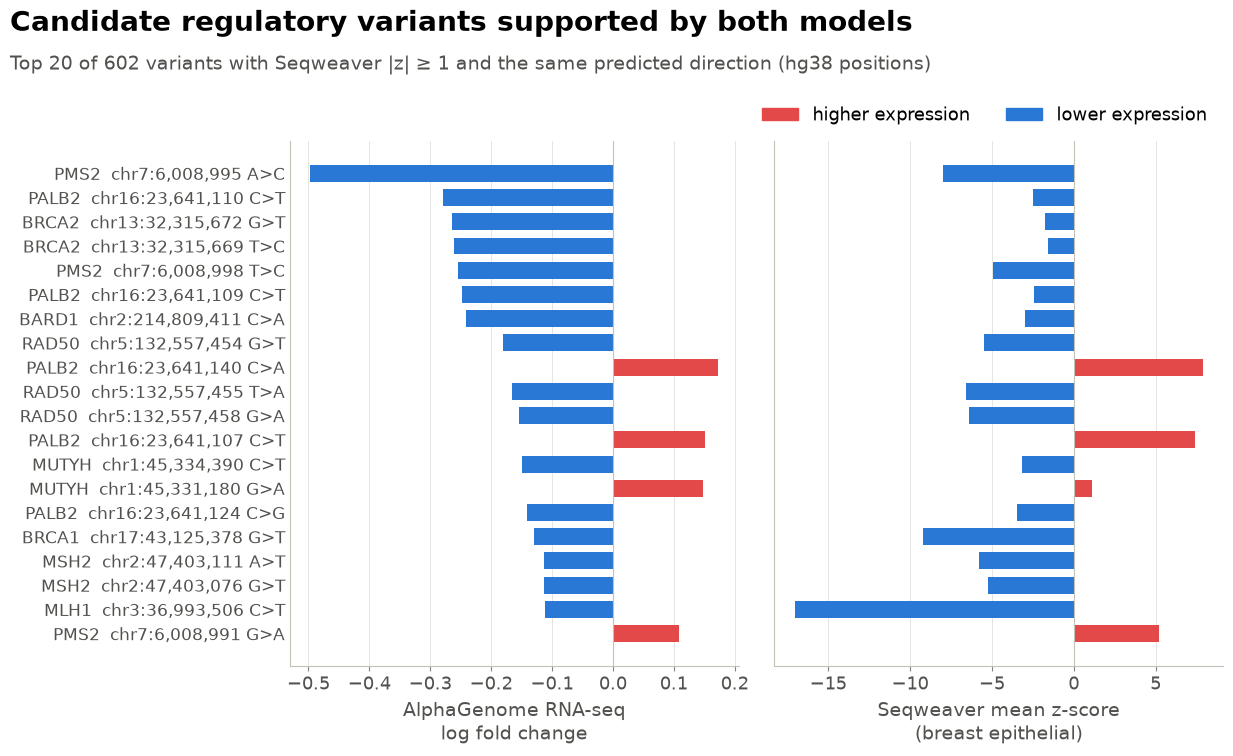

In [16]:
agree = VARIANTS[(VARIANTS.seqweaver_mean_z.abs() >= 1)
                 & (np.sign(VARIANTS.seqweaver_mean_z) == np.sign(VARIANTS.rna_lfc))]
top = agree.loc[agree.rna_lfc.abs().sort_values(ascending=False).index].head(20).iloc[::-1]
labels = [f'{g}  chr{s.split("_")[0]}:{p:,} {s.split("_")[2]}>{s.split("_")[3]}'
          for s, g, p in zip(top.index, top.gene, top.pos)]

fig, (ax, ax2) = plt.subplots(
    1, 2, figsize=SLIDE, sharey=True,
    gridspec_kw={'top': 0.82, 'left': 0.27, 'right': 0.97, 'bottom': 0.12, 'wspace': 0.08},
)
ax.barh(labels, top.rna_lfc, color=np.where(top.rna_lfc < 0, DOWN, UP), height=0.7)
ax.axvline(0, color=AXIS, lw=0.8)
ax.set_xlabel('AlphaGenome RNA-seq\nlog fold change')
ax2.barh(labels, top.seqweaver_mean_z, color=np.where(top.seqweaver_mean_z < 0, DOWN, UP), height=0.7)
ax2.axvline(0, color=AXIS, lw=0.8)
ax2.set_xlabel('Seqweaver mean z-score\n(breast epithelial)')
for a in (ax, ax2):
    a.grid(axis='x', color=GRID, lw=0.6)
    a.set_axisbelow(True)
    a.tick_params(axis='y', length=0, labelsize=12)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (UP, DOWN)]
ax2.legend(handles, ['higher expression', 'lower expression'], frameon=False, ncols=2,
           loc='lower right', bbox_to_anchor=(1, 1.0))
headline(fig, 'Candidate regulatory variants supported by both models',
         f'Top 20 of {len(agree):,} variants with Seqweaver |z| ≥ 1 and the same predicted direction (hg38 positions)')
save(fig, 'fig08_top_candidate_variants')
top.iloc[::-1][['gene', 'chrom', 'pos', 'rna_lfc', 'rna_quantile', 'AVI', 'AVI_quantile', 'seqweaver_mean_z', 'concordant']]

## Figure 9. AVI score on ClinVar variants in the 34 genes

**Caveat for the talk:** the AVI score is a supervised score built on AlphaGenome
outputs plus AlphaMissense, conservation and protein-truncation features. If ClinVar
was used to train it, this comparison is partly circular. It shows what the score
does, not an independent benchmark.

In [17]:
def score_clinvar(df, batch=5_000, workers=16):
    """AVI score for each ClinVar variant (cached in batches)."""
    cache = ATLAS_CACHE / 'clinvar_bridges34'
    cache.mkdir(parents=True, exist_ok=True)

    def one(row):
        for attempt in range(4):
            try:
                a = atlas_client.query_variant(
                    genome.Variant(row.chrom, row.pos, row.ref, row.alt),
                    requested_scorers=['AVI_SCORE'])['AVI_SCORE']
                return float(a.X[0, 0]), float(a.layers['quantiles'][0, 0])
            except ValueError:
                break
            except Exception:
                time.sleep(3 * (attempt + 1))
        return float('nan'), float('nan')

    frames = []
    for i in range(0, len(df), batch):
        path = cache / f'batch_{i:06d}.parquet'
        if not path.exists():
            part = df.iloc[i:i + batch].copy()
            with concurrent.futures.ThreadPoolExecutor(workers) as ex:
                res = list(ex.map(one, part.itertuples()))
            part['AVI'], part['AVI_quantile'] = [r[0] for r in res], [r[1] for r in res]
            part.to_parquet(path)
        frames.append(pd.read_parquet(path))
    return pd.concat(frames, ignore_index=True)


CLINVAR_AVI = score_clinvar(CLINVAR).dropna(subset=['AVI'])
CLINVAR_AVI['variant_class'] = np.select(
    [CLINVAR_AVI.consequence.isin(CODING_CONSEQUENCES),
     CLINVAR_AVI.consequence.isin(SPLICE_CONSEQUENCES)],
    ['coding', 'canonical splice site'], 'other non-coding',
)
CLINVAR_AVI.groupby(['variant_class', 'clin_group']).size().unstack()

clin_group,B/LB,P/LP,VUS
variant_class,,,
canonical splice site,34.0,3018.0,228.0
coding,20309.0,8441.0,NaN
other non-coding,28314.0,509.0,4779.0


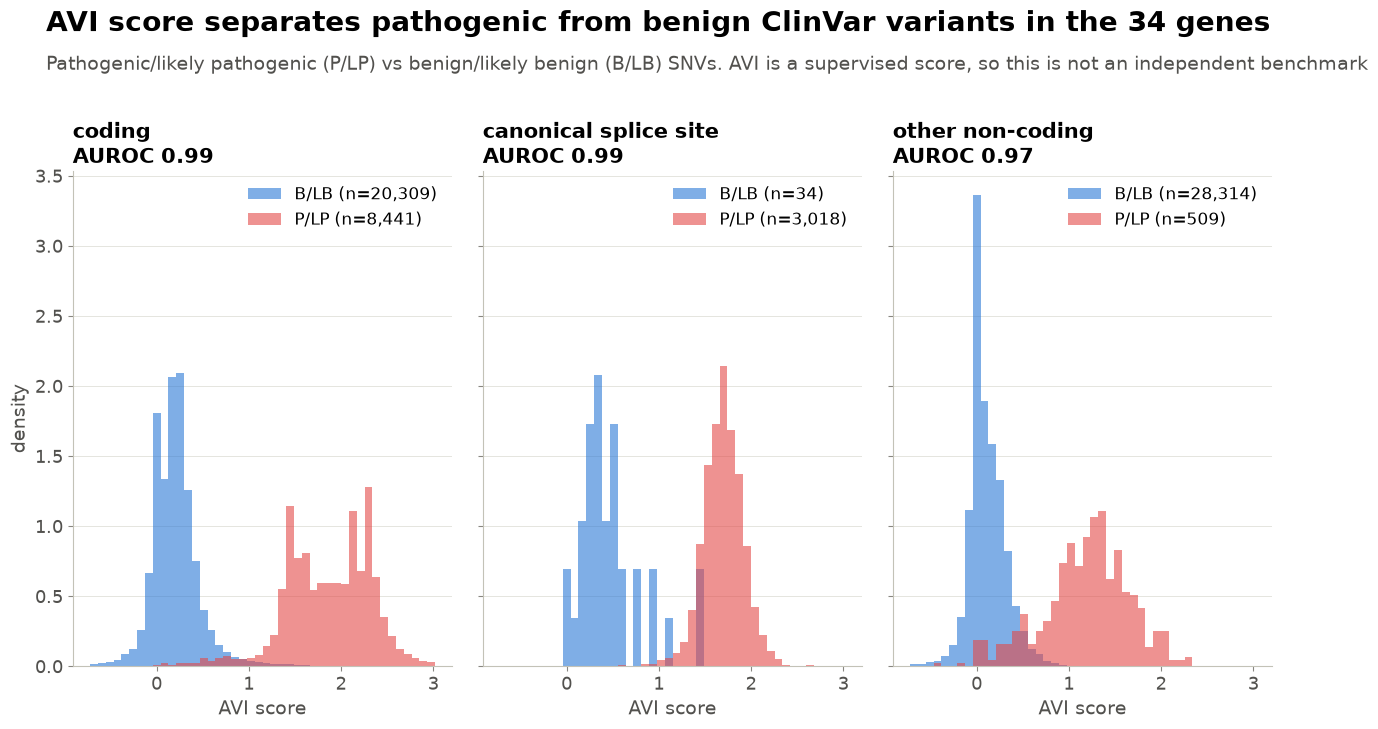

In [18]:
def auroc(pos, neg):
    """Probability that a random P/LP variant scores above a random B/LB variant."""
    ranks = pd.concat([pos, neg]).rank()
    return (ranks.iloc[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg))


CLASSES = ['coding', 'canonical splice site', 'other non-coding']
GROUP_COLORS = {'B/LB': BLUE, 'P/LP': UP}
fig, axes = plt.subplots(
    1, 3, figsize=SLIDE, sharey=True,
    gridspec_kw={'top': 0.78, 'left': 0.08, 'right': 0.98, 'bottom': 0.12, 'wspace': 0.08},
)
bins = np.linspace(CLINVAR_AVI.AVI.quantile(0.001), CLINVAR_AVI.AVI.quantile(0.999), 45)
for ax, cls in zip(axes, CLASSES):
    sub = CLINVAR_AVI[CLINVAR_AVI.variant_class == cls]
    groups = {g: sub.AVI[sub.clin_group == g] for g in GROUP_COLORS}
    for g, color in GROUP_COLORS.items():
        ax.hist(groups[g], bins=bins, density=True, color=color, alpha=0.6, lw=0,
                label=f'{g} (n={len(groups[g]):,})')
    ax.set_title(f'{cls}\nAUROC {auroc(groups["P/LP"], groups["B/LB"]):.2f}')
    ax.set_xlabel('AVI score')
    ax.legend(frameon=False, loc='upper right', fontsize=12)
    ax.grid(axis='y', color=GRID, lw=0.6)
    ax.set_axisbelow(True)
axes[0].set_ylabel('density')
headline(fig, 'AVI score separates pathogenic from benign ClinVar variants in the 34 genes',
         'Pathogenic/likely pathogenic (P/LP) vs benign/likely benign (B/LB) SNVs. '
         'AVI is a supervised score, so this is not an independent benchmark')
save(fig, 'fig09a_clinvar_avi_by_class')

gene
ATM      167
NF1      141
BRCA2     83
BRCA1     71
CHEK2     70
BRIP1     61
PTEN      55
MLH1      52
CDH1      48
RAD50     46
MSH2      45
BARD1     44
PMS2      41
MSH6      40
MUTYH     36
Name: count, dtype: int64

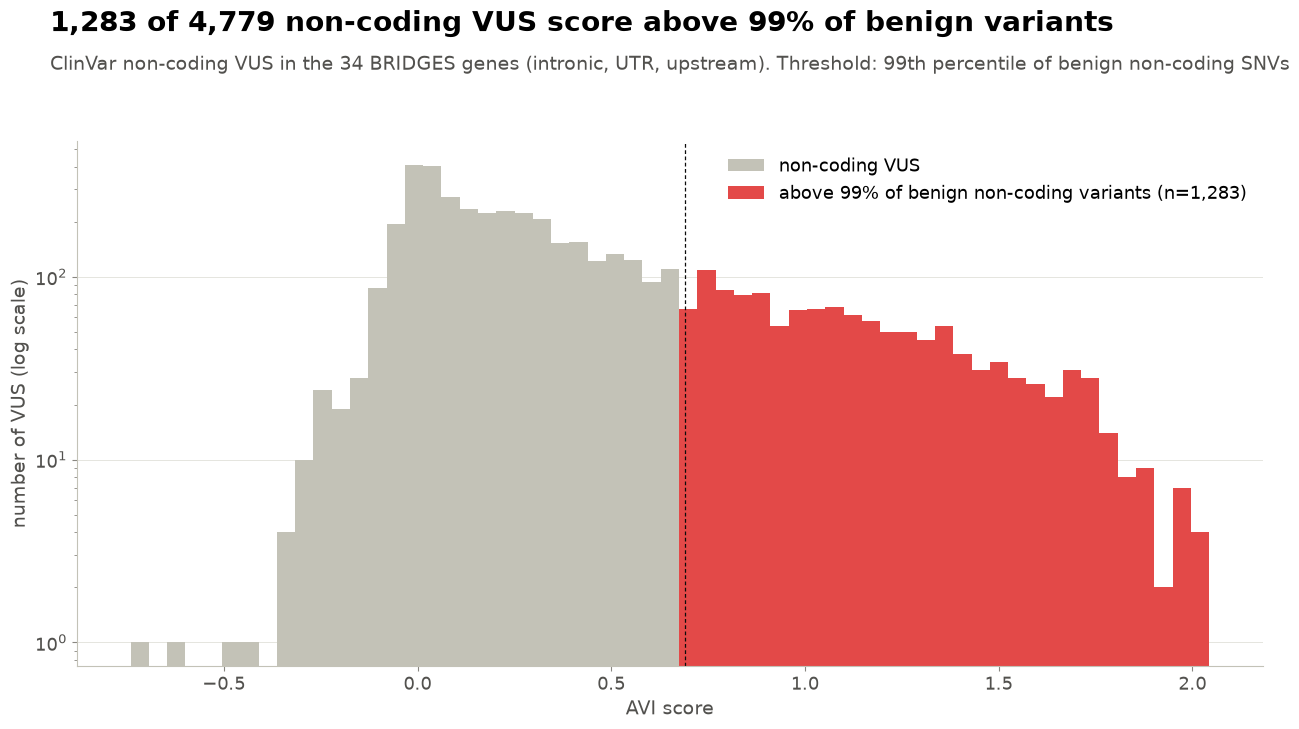

In [19]:
# Non-coding VUS: how many score like non-coding P/LP variants?
noncoding = CLINVAR_AVI[CLINVAR_AVI.variant_class == 'other non-coding']
benign, vus = noncoding.AVI[noncoding.clin_group == 'B/LB'], noncoding[noncoding.clin_group == 'VUS']
threshold = benign.quantile(0.99)
flagged = vus[vus.AVI > threshold]

fig, ax = plt.subplots(figsize=SLIDE, gridspec_kw={'top': 0.82, 'left': 0.08, 'right': 0.97, 'bottom': 0.12})
bins = np.linspace(noncoding.AVI.quantile(0.001), noncoding.AVI.quantile(0.9995), 60)
ax.hist(vus.AVI[vus.AVI <= threshold], bins=bins, color=AXIS, lw=0, label='non-coding VUS')
ax.hist(flagged.AVI, bins=bins, color=UP, lw=0,
        label=f'above 99% of benign non-coding variants (n={len(flagged):,})')
ax.axvline(threshold, color=INK, lw=0.9, ls=(0, (3, 2)))
ax.set_yscale('log')
ax.set_xlabel('AVI score')
ax.set_ylabel('number of VUS (log scale)')
ax.legend(frameon=False, loc='upper right')
ax.grid(axis='y', color=GRID, lw=0.6)
ax.set_axisbelow(True)
headline(fig, f'{len(flagged):,} of {len(vus):,} non-coding VUS score above 99% of benign variants',
         'ClinVar non-coding VUS in the 34 BRIDGES genes (intronic, UTR, upstream). '
         'Threshold: 99th percentile of benign non-coding SNVs')
save(fig, 'fig09b_clinvar_noncoding_vus')
flagged.gene.value_counts().head(15)

## Figure 10. Why is a variant flagged?

The Atlas returns the contribution of each input feature to the AVI score of a variant.

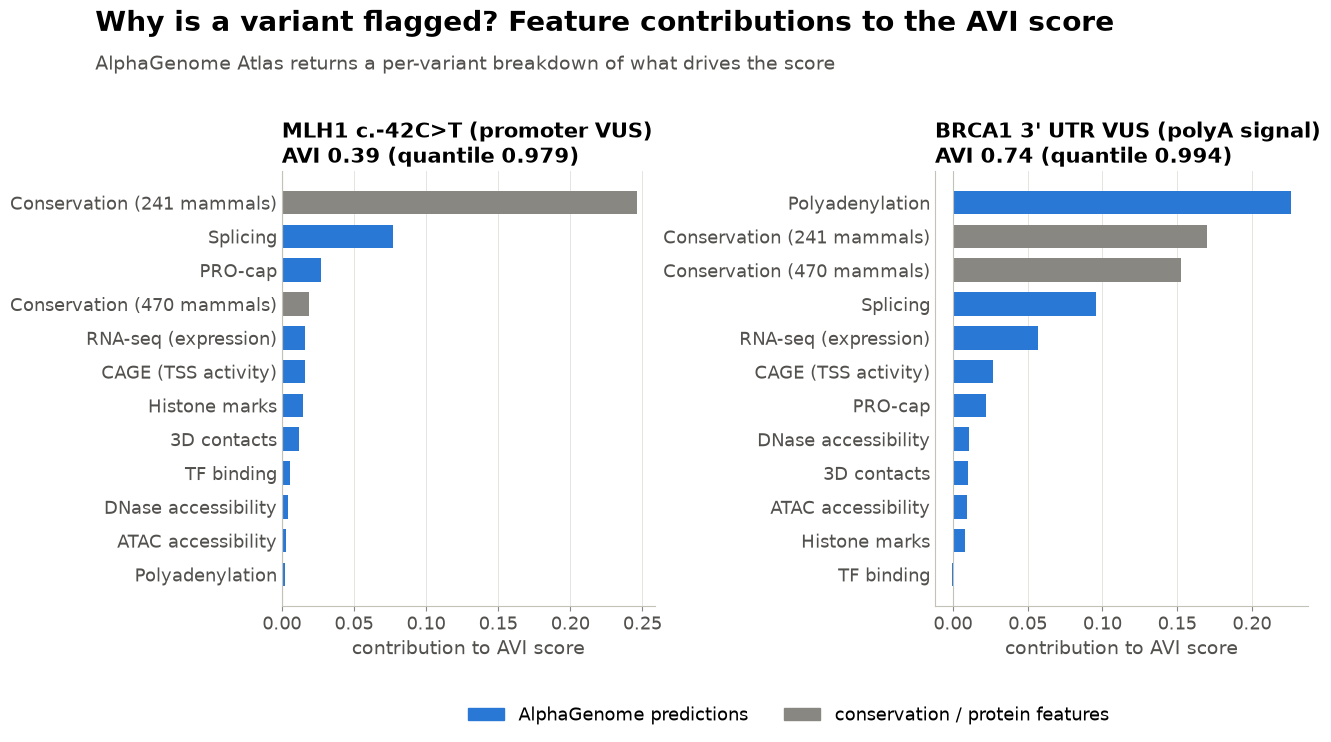

In [20]:
FEATURE_LABELS = {
    'MERGED_SPLICING': 'Splicing', 'MAX_ABS_ATAC': 'ATAC accessibility',
    'MAX_ABS_CONTACT_MAPS': '3D contacts', 'MAX_ABS_DNASE': 'DNase accessibility',
    'MAX_ABS_CHIP_TF': 'TF binding', 'MAX_ABS_CHIP_HISTONE': 'Histone marks',
    'MAX_ABS_CAGE': 'CAGE (TSS activity)', 'MAX_ABS_PROCAP': 'PRO-cap',
    'MAX_ABS_RNA_SEQ': 'RNA-seq (expression)', 'MAX_ABS_POLYADENYLATION': 'Polyadenylation',
    'ALPHAMISSENSE': 'AlphaMissense', 'CACTUS_241_WAY': 'Conservation (241 mammals)',
    'PROTEIN_TERMINATION': 'Protein truncation', 'START_LOST': 'Start lost',
    'STOP_LOST': 'Stop lost', 'PHASTCONS_470_WAY': 'Conservation (470 mammals)',
    'IS_INSERTION': 'Insertion', 'IS_DELETION': 'Deletion',
}
ALPHAGENOME_FEATURES = [k for k in FEATURE_LABELS if k.startswith(('MAX_ABS', 'MERGED'))]
feature_names = atlas_client.scorer_metadata()['AVI_SCORE_FEATURE_IMPORTANCE'].track_metadata['name'].tolist()


def avi_explanation(variant):
    r = atlas_client.query_variant(
        variant, requested_scorers=['AVI_SCORE', 'AVI_SCORE_FEATURE_IMPORTANCE'])
    importance = pd.Series(r['AVI_SCORE_FEATURE_IMPORTANCE'].X[0], index=feature_names)
    avi = r['AVI_SCORE']
    return importance, float(avi.X[0, 0]), float(avi.layers['quantiles'][0, 0])


examples = [(mlh1_vus, 'MLH1 c.-42C>T (promoter VUS)'),
            (brca1_variant, "BRCA1 3' UTR VUS (polyA signal)")]
fig, axes = plt.subplots(
    1, 2, figsize=SLIDE,
    gridspec_kw={'top': 0.78, 'left': 0.2, 'right': 0.97, 'bottom': 0.2, 'wspace': 0.75},
)
for ax, (variant, label) in zip(axes, examples):
    importance, score, quantile = avi_explanation(variant)
    importance = importance[importance.abs() > 1e-4].sort_values()
    colors = [BLUE if f in ALPHAGENOME_FEATURES else MUTED for f in importance.index]
    ax.barh([FEATURE_LABELS[f] for f in importance.index], importance, color=colors, height=0.7)
    ax.axvline(0, color=AXIS, lw=0.8)
    ax.set_title(f'{label}\nAVI {score:.2f} (quantile {quantile:.3f})')
    ax.set_xlabel('contribution to AVI score')
    ax.grid(axis='x', color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(axis='y', length=0)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, MUTED)]
fig.legend(handles, ['AlphaGenome predictions', 'conservation / protein features'],
           frameon=False, loc='lower center', bbox_to_anchor=(0.58, 0.02), ncols=2)
headline(fig, 'Why is a variant flagged? Feature contributions to the AVI score',
         'AlphaGenome Atlas returns a per-variant breakdown of what drives the score')
save(fig, 'fig10_avi_feature_contributions')

In [21]:
sorted(p.name for p in FIGDIR.glob('*.png'))

['fig01_brca1_predicted_tracks.png',
 'fig02a_variant_effect_MLH1_promoter_VUS.png',
 'fig02b_variant_effect_BRCA1_noncoding_VUS.png',
 'fig03_atlas_locus_ism_BRCA1.png',
 'fig03_atlas_locus_ism_BRCA2.png',
 'fig03_atlas_locus_ism_TP53.png',
 'fig04_atlas_BRCA1_promoter_base_resolution.png',
 'fig05_promoter_ism_34_genes.png',
 'fig06_coding_vs_noncoding.png',
 'fig07_seqweaver_vs_alphagenome.png',
 'fig08_top_candidate_variants.png',
 'fig09a_clinvar_avi_by_class.png',
 'fig09b_clinvar_noncoding_vus.png',
 'fig10_avi_feature_contributions.png']